# Compare sampling distributions of ICESat-2 obs considered in `run_boreal_biomass` 
### the `MAAP` algorithm running the latest vesion of `mapBoreal`
the are ICESat-2 obs with contemporaneous HLS extracted to them : from multi- and single-yr sets used in rF models  

Paul Montesano, PhD | Oct 2025

In [72]:
library(tidyverse)
library(data.table)
library(viridis)
library(sf)
library(mapproj)
library(rgdal)
library(raster)
library(aws.s3)
library(fs)
library(sfarrow)
library(arrow)
library(lubridate)
library(ggspatial)

In [73]:
find_parquet_in_s3_dir <- function(s3_path, aws_access_key = NULL, aws_secret_key = NULL, 
                                  aws_region = "us-west-2") {
  
  # Set credentials if provided
  if (!is.null(aws_access_key) && !is.null(aws_secret_key)) {
    Sys.setenv("AWS_ACCESS_KEY_ID" = aws_access_key)
    Sys.setenv("AWS_SECRET_ACCESS_KEY" = aws_secret_key) 
    Sys.setenv("AWS_DEFAULT_REGION" = aws_region)
  }
  
  # Parse S3 path to get bucket and prefix
  # Remove s3:// prefix
  s3_clean <- gsub("^s3://", "", s3_path)
  
  # Split into components
  path_parts <- strsplit(s3_clean, "/")[[1]]
  
  # Check if we have at least a bucket
  if (length(path_parts) == 0) {
    cat("❌ Invalid S3 path: no components found\n")
    return(NULL)
  }
  
  bucket <- path_parts[1]
  
  # Get directory (everything except the filename if it's a file path)
  if (length(path_parts) > 1) {
    # If the last part looks like a file (has extension), exclude it
    if (grepl("\\.[a-zA-Z0-9]+$", path_parts[length(path_parts)])) {
      # It's a file, so take everything except the last part
      prefix_parts <- path_parts[2:(length(path_parts)-1)]
    } else {
      # It's a directory, take everything after bucket
      prefix_parts <- path_parts[-1]
    }
    
    if (length(prefix_parts) > 0) {
      prefix <- paste(prefix_parts, collapse = "/")
      # Add trailing slash
      if (!endsWith(prefix, "/")) {
        prefix <- paste0(prefix, "/")
      }
    } else {
      prefix <- ""
    }
  } else {
    prefix <- ""
  }
  
  cat("🔍 Searching in bucket:", bucket, "\n")
  cat("🔍 Prefix:", prefix, "\n")
  
  # List objects in the directory - with more robust error handling
  tryCatch({
    
    # Try using get_bucket directly instead of get_bucket_df
    cat("📡 Attempting to list objects...\n")
    
    bucket_contents <- get_bucket(
      bucket = bucket, 
      prefix = prefix, 
      max = Inf,
      region = aws_region
    )
    
    if (length(bucket_contents) == 0) {
      cat("📂 No objects found in directory\n")
      return(NULL)
    }
    
    cat("📂 Found", length(bucket_contents), "object(s)\n")
    
    # Extract keys from the bucket contents
    object_keys <- sapply(bucket_contents, function(x) x$Key)
    
    cat("📂 Object keys retrieved\n")
    
    # Filter for .parquet files
    parquet_keys <- object_keys[grepl("\\.parquet$", object_keys, ignore.case = TRUE)]
    
    if (length(parquet_keys) == 0) {
      cat("❌ No .parquet files found in directory\n")
      cat("   Available files:\n")
      print(head(object_keys, 10))
      return(NULL)
    }
    
    # Sort by filename to ensure consistent order
    parquet_keys <- sort(parquet_keys)
    
    # Return full S3 paths
    parquet_paths <- paste0("s3://", bucket, "/", parquet_keys)
    
    cat("✅ Found", length(parquet_paths), ".parquet file(s):\n")
    for (path in parquet_paths) {
      cat("   ", path, "\n")
    }
    
    return(parquet_paths)
    
  }, error = function(e) {
    cat("❌ Error listing S3 objects:", e$message, "\n")
    cat("   Error class:", class(e), "\n")
    cat("   Bucket:", bucket, "\n")
    cat("   Prefix:", prefix, "\n")
    cat("   Region:", aws_region, "\n")
    
    # Try to check if it's a credentials issue
    cat("\n🔑 Checking AWS credentials:\n")
    cat("   AWS_ACCESS_KEY_ID set:", nchar(Sys.getenv("AWS_ACCESS_KEY_ID")) > 0, "\n")
    cat("   AWS_SECRET_ACCESS_KEY set:", nchar(Sys.getenv("AWS_SECRET_ACCESS_KEY")) > 0, "\n")
    cat("   AWS_DEFAULT_REGION:", Sys.getenv("AWS_DEFAULT_REGION"), "\n")
    
    return(NULL)
  })
}

In [102]:
SUBSET_3x3_TILES_WINDOW <- function(boreal_tiles, FOCAL_TILE){
    
    # Select the focal tile (replace with your criteria)
    focal_tile <- boreal_tiles %>%
      filter(tile_num == FOCAL_TILE)  # or other criteria

    # Find adjacent tiles that touch the focal tile
    adjacent_tiles <- boreal_tiles %>%
      filter(st_touches(., focal_tile, sparse = FALSE)[,1])
    
    # Combine focal and adjacent tiles
    boreal_tiles_focal <- bind_rows(
      focal_tile %>% mutate(tile_type = "focal"),
      adjacent_tiles %>% mutate(tile_type = "adjacent")
    )
    }

# Function to get obs and combine
GET_OBS_AND_COMBINE <- function(TINDEX_FN, FOCAL_TILE, BOREAL_TILES_SF,
                                DO_MAP=TRUE, BY_YEAR=TRUE,
                                MODELLING_STRATEGY='single year', 
                                JOIN_COLS = c('lon_rnd','lat_rnd') # Identify the colums for joining the smaller training obs to the larger candidate obs (from merge neighbors) for both single-yr and multiyr datasets
                               ){

    Sys.setenv("AWS_DEFAULT_REGION" = "us-west-2") 

    IDENTIFIER = str_split(str_split(TINDEX_FN, 'BOREAL_MAP/')[[1]][2], '/full_')[[1]][1]

    TINDEX <- aws.s3::s3read_using(read.csv, object = TINDEX_FN)

    #boreal_tiles_focal = BOREAL_TILES_SF %>% filter(tile_num == FOCAL_TILE)

    boreal_tiles_focal = SUBSET_3x3_TILES_WINDOW(BOREAL_TILES_SF, FOCAL_TILE)
    
    
    # Usage
    s3_path <- (TINDEX %>% filter(tile_num == FOCAL_TILE))$s3_path
    
    parquet_files <- find_parquet_in_s3_dir(s3_path, aws_region = 'us-west-2')
    
    # Get the first parquet file - merge neighbors, which is much larger than the 2nd (subset used for training)
    if (!is.null(parquet_files) && length(parquet_files) > 0) {
      mergeneighbors_parquet <- parquet_files[1]
      cat("Using:", mergeneighbors_parquet, "\n")
      mergeneighbors <- st_read_parquet(mergeneighbors_parquet) %>%
                {st_crs(.) <- crs_canalb_fromraster; .} %>%
                st_transform(crs=4326) %>% 
                mutate(RH_98 = h_canopy) %>%
                dplyr::select(RH_98, m, y, doy, geometry) %>% 
                dplyr::mutate(
                        AGB = NA,
                        modelling_strategy = MODELLING_STRATEGY,
                        file_src = 'mergeneighbors'
                ) %>%
                dplyr::mutate(
                    lon = st_coordinates(.)[,1],  
                    lat = st_coordinates(.)[,2],
                    lon_rnd = round(st_coordinates(.)[,1], 8),  # Round to 6 decimal places
                    lat_rnd = round(st_coordinates(.)[,2], 8)
                    ) %>% as.data.frame()
        
      # the 2nd file - training subset
      train_parquet <- parquet_files[2]
      #cat("Using:", train_parquet, "\n")
      train <- read_parquet(train_parquet) %>%
                dplyr::select(RH_98, AGB, lat, lon) %>% 
                dplyr::mutate(
                        y = NA,
                        m = NA,
                        doy = NA,
                        modelling_strategy = MODELLING_STRATEGY,
                        file_src = 'train'
                ) %>%
                st_as_sf(coords = c("lon", "lat"), crs = 4326) %>%
                dplyr::mutate(
                    lon_rnd = round(st_coordinates(.)[,1], 8),  # Round to 6 decimal places
                    lat_rnd = round(st_coordinates(.)[,2], 8)
                    ) %>% as.data.frame()
    }
    
    # Combine the 2 pqrquet tables: merge neighbers and training
    gdf = mergeneighbors %>%
                ## Join apprach 1
                # st_join(singleyr_train %>% dplyr::select(file_src, RH_98, AGB, geometry) %>% mutate(geom2 = geometry), join = st_nearest_feature) %>%
                # # Calculate actual distance to verify reasonable match
                # mutate(
                #   match_distance = as.numeric(st_distance(geometry, geom2, by_element = TRUE))
                # ) %>%
                # mutate(
                        # Identify the
                        # - training obs for which we have both RH_98 and AGB 
                        # - candidate obs (from mergeneighbors) do not have AGB; only when they are chosen for training is AGB computed before the rF modelling        #   obs_class = ifelse(match_distance <= 5, 'training obs.', 'candidate obs.'),  # 1m threshold
                #   RH_98 = ifelse(match_distance <= 5, RH_98.y, RH_98.x)  ,
                #   AGB = ifelse(match_distance <= 5, AGB.y, NA) 
                # ) 
                # Join approach 2
                dplyr::left_join(train, by = JOIN_COLS) %>%
                dplyr::mutate(
                    # Identify the
                    # - training obs for which we have both RH_98 and AGB 
                    # - candidate obs (from mergeneighbors) do not have AGB; only when they are chosen for training is AGB computed before the rF modelling
                    #file_src = ifelse((!is.na(file_src.y) & !is.na(file_src.x)), 'both', ifelse((!is.na(file_src.y) & is.na(file_src.x)),'train','mergeneighors')),
                    file_src = ifelse((!is.na(file_src.x) & !is.na(file_src.y)), 'both', ifelse((!is.na(file_src.x) & is.na(file_src.y)),'mergeneighors', ifelse((is.na(file_src.x) & is.na(file_src.y)),'both NA','other case'))),
                    obs_class = ifelse(!is.na(file_src.y), 'candidate training', 'filtered-out'),
                    RH_98 = ifelse(RH_98.y - RH_98.x <= 1, RH_98.y, NA)  ,
                    AGB = ifelse(RH_98.y - RH_98.x <= 1, AGB.y, NA) ,
                    tile_num = FOCAL_TILE
                ) %>% 
                st_as_sf(coords = c("lon", "lat"), crs = 4326)

    gdf = gdf %>% 
                dplyr::mutate(
                    y = y.x,
                    doy = doy.x,
                    modelling_strategy = modelling_strategy.x,
                    #file_src = file_src.y, 
                    date = as.Date(paste(y.x, doy.x), format = "%Y %j"), # .x b/c they come from mergeneighbors
                    month = lubridate::month(date, label = TRUE)
                  ) %>%
                dplyr::select(-contains(".x"), -contains(".y"))

    #print(names(gdf))

    GROUP_COLS = c('modelling_strategy', 'obs_class')
    if(BY_YEAR){
        GROUP_COLS = c('modelling_strategy', 'obs_class', 'y')
        }
    print(GROUP_COLS)
    smry = gdf %>%
        group_by(across(all_of(GROUP_COLS))) %>%
        summarise(
            n_obs = n(),
            max_RH_98 = max(RH_98),
            min_RH_98 = min(RH_98),
            mean_RH_98 = mean(RH_98),
            median_RH_98 = median(RH_98),
            max_AGB = max(AGB),
            min_AGB = min(AGB),
            mean_AGB = mean(AGB),
            median_AGB = median(AGB),
            #pct98th_AGB = quantile(AGB, probs = c(0.98)),
            min_doy = min(doy),
            max_doy = max(doy),
            median_doy = median(doy),
            min_year = min(y),
            median_year = median(y),
            max_year = max(y)
        )# %>%
        #     mutate(
        #         min_date = as.Date(paste(min_year, min_doy), format = "%Y %j"),
        #         median_date = as.Date(paste(median_year, median_doy), format = "%Y %j"),
        #         max_date = as.Date(paste(max_year, max_doy), format = "%Y %j")
        #     )

    if(DO_MAP){
        map_facets = DO_MAP_FACETS(gdf, smry, boreal_tiles_focal, FOCAL_TILE, IDENTIFIER, BY_YEAR=BY_YEAR)   
        #print(map_facets)
        }
    
    return(list(gdf, map_facets))
    }

DO_MAP_FACETS <- function(GDF, SMRY, BOREAL_TILES_FOCAL, FOCAL_TILE, IDENTIFIER, BY_YEAR=TRUE){
    
    map_facets = ggplot(GDF) +
        geom_sf(data=BOREAL_TILES_FOCAL %>% filter(tile_num == FOCAL_TILE)%>% st_transform(crs=4326), fill='gray60', alpha=0.2) +
        geom_sf(aes(color=factor(month)), size=0.01) +
        geom_sf(data=BOREAL_TILES_FOCAL %>% st_transform(crs=4326), fill=NA) + 
        geom_sf_label(data=BOREAL_TILES_FOCAL %>% filter(tile_num == FOCAL_TILE), aes(label=tile_num), size=3) +
        labs(
            #title='Filtered ICESat-2 obs considered in run_boreal_biomass', 
            subtitle=paste0('Tile ',FOCAL_TILE, ' (',IDENTIFIER,')'), color='Month of\nICESat-2 obs.') + 
        theme_bw() + 
        theme(plot.subtitle = element_text(size=8), axis.title = element_blank(), axis.text.x = element_text(angle=90)) + 
        guides(color = guide_legend(override.aes = list(size = 8))) +
        geom_label(data=SMRY, aes(x=Inf, y=Inf, label=paste0('n=',scales::comma(n_obs),'\nmax AGB (ICESat-2)=',round(max_AGB,1))
                                      #,'\npct98 AGB (ICESat-2)=',round(pct98th_AGB,1)
                                     ), hjust=1, vjust=1, size=3, alpha=0.5) 
    
    if(BY_YEAR){

        map_facets = map_facets +
            facet_grid(interaction(obs_class,modelling_strategy) ~ y)
    }else{
        map_facets = map_facets + 
            facet_grid(interaction(obs_class,modelling_strategy) ~ .)
        }
    
    return(map_facets + theme(strip.text = element_text(size=12)) )
    }


In [75]:
source('/projects/code/3dsi/boreal_map_functions.R') 
source('/projects/code/maap_tools/notebooks/boreal_smry_functions.r') 

[1] "MAAP"
[1] "MAAP"


In [76]:
library(terra)

### Rasters have projection that is read correctly by R - vectors dont i guess

In [77]:
r_fn = 's3://maap-ops-workspace/aliz237/dps_output/run_boreal_biomass_map/v3.0.0/AGB_H30_2020/full_run/2025/06/09/23/20/45/978817/boreal_agb_2020_202506091749528331_0001897.tif'
raster_proj <- rast(r_fn)
raster_proj

class       : SpatRaster 
dimensions  : 3000, 3000, 2  (nrow, ncol, nlyr)
resolution  : 30, 30  (x, y)
extent      : -3501478, -3411478, 4743304, 4833304  (xmin, xmax, ymin, ymax)
coord. ref. : +proj=aea +lat_0=40 +lon_0=180 +lat_1=50 +lat_2=70 +x_0=0 +y_0=0 +ellps=GRS80 +towgs84=0,0,0,0,0,0,0 +units=m +no_defs 
source      : boreal_agb_2020_202506091749528331_0001897.tif 
names       :     lyr.1,     lyr.1 
min values  :  10.64021,  3.242516 
max values  : 194.10417, 32.210133 

In [78]:
crs_canalb_fromraster = crs(raster_proj)

In [79]:
boreal_tile_DAAC_path = '/projects/shared-buckets/montesano/databank/boreal_tiles_v004_model_ready.gpkg'
boreal_tiles = st_read(boreal_tile_DAAC_path)
st_crs(boreal_tiles) <- crs_canalb_fromraster #crs_canalb

boreal_tiles = st_transform(boreal_tiles, crs=4326)

Reading layer `boreal_tiles_v004_model_ready' from data source 
  `/projects/shared-buckets/montesano/databank/boreal_tiles_v004_model_ready.gpkg' 
  using driver `GPKG'
Simple feature collection with 4956 features and 5 fields
Geometry type: POLYGON
Dimension:     XY
Bounding box:  xmin: -6111478 ymin: 1233304 xmax: 6308522 ymax: 10323300
Projected CRS: unnamed


### Choose tindex files for consideration

In [80]:
AGB_singleyr_tindex_master_fn = 's3://maap-ops-workspace/shared/montesano/DPS_tile_lists/BOREAL_MAP/v3.2.0/AGB_H30_2020/full_run/AGB_tindex_master.csv'
AGB_multiyr_tindex_master_fn = 's3://maap-ops-workspace/shared/montesano/DPS_tile_lists/BOREAL_MAP/v3.1.0/AGB_H30_2020/full_run_niter30_multiyear_atl08v6/AGB_tindex_master.csv'

In [81]:
Sys.setenv("AWS_DEFAULT_REGION" = "us-west-2") 

AGB_singleyr_tindex <- aws.s3::s3read_using(read.csv, object = AGB_singleyr_tindex_master_fn)
AGB_multiyr_tindex <- aws.s3::s3read_using(read.csv, object = AGB_multiyr_tindex_master_fn)

In [82]:
FOCAL_TILE = 1206
FOCAL_TILE = 3597 # larch forest on russia/china border in boreal - check dates of ICESat-2 and larch/DNT senescence
FOCAL_TILE = 4284
FOCAL_TILE = 1841
#FOCAL_TILE = 1842

In [83]:
# map_focal = ggplot() + 
#     #ggspatial::annotation_map_tile(type = "esri", zoom = 12) +  # ESRI World Imagery
#     geom_sf(data=boreal_tiles_focal %>% st_transform(crs=4326), fill=NA) +
#     geom_sf_label(data=boreal_tiles %>% filter(tile_num == FOCAL_TILE), aes(label=tile_num)) +
#     theme_bw()

# map_focal

### 1 tile example - single-yr obs

In [95]:
m = st_read_parquet('s3://maap-ops-workspace/aliz237/dps_output/run_boreal_biomass_map/v3.1.0/AGB_H30_2020/full_run/2025/08/19/22/01/53/752599/atl08_006_030m_2020_2020_06_09_filt_covars_merge_neighbors_002832.parquet')
names(m)

[1] "solar_elevation"      "h_te_median"          "veg_ph_count"        
 [4] "gt"                   "ph_count"             "spot"                
 [7] "extent_id"            "cycle"                "gnd_ph_count"        
[10] "h_canopy"             "landcover"            "h_max_canopy"        
[13] "h_mean_canopy"        "snowcover"            "canopy_openness"     
[16] "segment_id"           "x_atc"                "rgt"                 
[19] "h_min_canopy"         "h_dif_ref"            "msw_flag"            
[22] "sigma_topo"           "segment_landcover"    "segment_snowcover"   
[25] "rh25"                 "rh50"                 "rh60"                
[28] "rh70"                 "rh75"                 "rh80"                
[31] "rh85"                 "rh90"                 "rh95"                
[34] "h_canopy_uncertainty" "segment_cover"        "h_te_uncertainty"    
[37] "y"                    "m"                    "d"                   
[40] "doy"                  "beam_type"            "elevation"           
[43] "slope"                "tsri"                 "tpi"                 
[46] "slopemask"            "Blue"                 "Green"               
[49] "Red"                  "NIR"                  "SWIR"                
[52] "SWIR2"                "NDVI"                 "SAVI"                
[55] "MSAVI"                "NDMI"                 "EVI"                 
[58] "NBR"                  "NBR2"                 "TCB"                 
[61] "TCG"                  "TCW"                  "ValidMask"           
[64] "Xgeo"                 "Ygeo"                 "JulianDate"          
[67] "yearDate"             "vv_median_frozen"     "vh_median_frozen"    
[70] "vv_median_summer"     "vh_median_summer"     "vv_median_shoulder"  
[73] "vh_median_shoulder"   "n_frozen"             "n_summer"            
[76] "n_shoulder"           "binsize"              "num_bins"            
[79] "X__index_level_0__"   "geometry"

🔍 Searching in bucket: maap-ops-workspace prefix: aliz237/dps_output/run_boreal_biomass_map/v3.1.0/AGB_H30_2020/full_run/2025/08/19/22/01/53/752599/ 
✅ Found 2 .parquet file(s):
    s3://maap-ops-workspace/aliz237/dps_output/run_boreal_biomass_map/v3.1.0/AGB_H30_2020/full_run/2025/08/19/22/01/53/752599/atl08_006_030m_2020_2020_06_09_filt_covars_merge_neighbors_002832.parquet 
    s3://maap-ops-workspace/aliz237/dps_output/run_boreal_biomass_map/v3.1.0/AGB_H30_2020/full_run/2025/08/19/22/01/53/752599/boreal_agb_2020_202508191755663225_0002832_train.parquet 
[1] "modelling_strategy" "obs_class"          "y"                 


`summarise()` has grouped output by 'modelling_strategy', 'obs_class'. You can
override using the `.groups` argument.


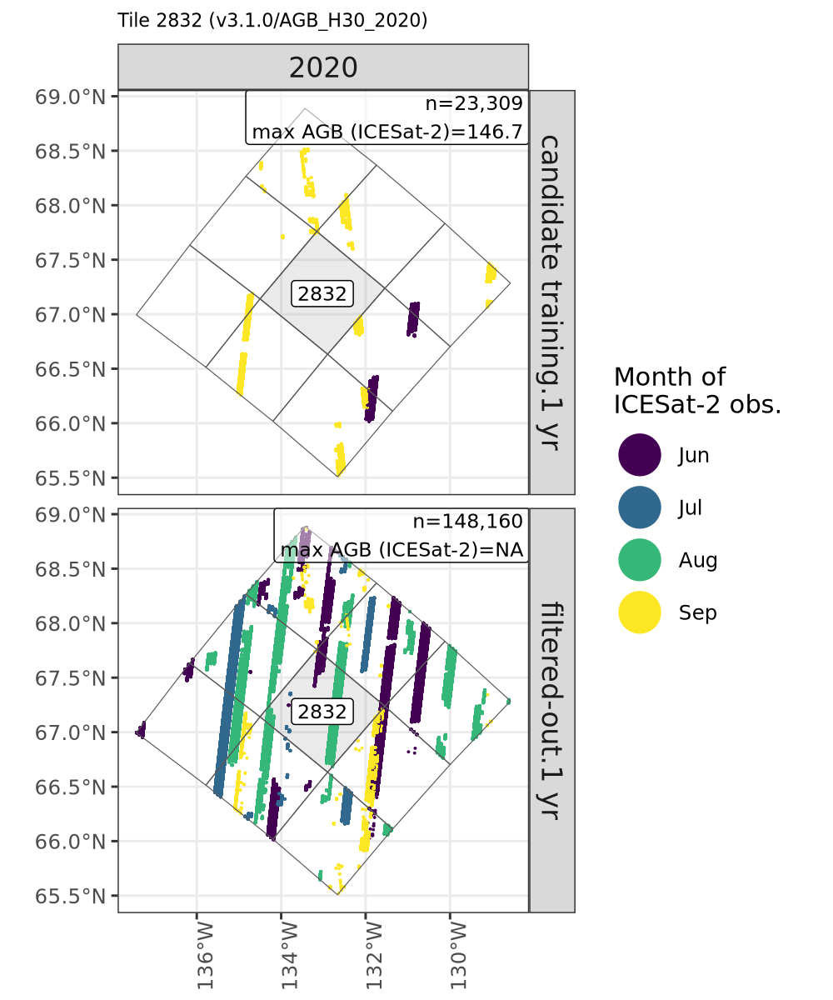

In [103]:
options(repr.plot.width = 5, repr.plot.height = 6, repr.plot.res = 200 , warn = -1 )

results_singleyr = GET_OBS_AND_COMBINE('s3://maap-ops-workspace/shared/montesano/DPS_tile_lists/BOREAL_MAP/v3.1.0/AGB_H30_2020/full_run/AGB_tindex_master.csv', 2832, boreal_tiles, MODELLING_STRATEGY='1 yr', BY_YEAR=TRUE)
results_singleyr[[2]]

### 1 tile example - multi-yr obs

🔍 Searching in bucket: maap-ops-workspace prefix: montesano/dps_output/run_boreal_biomass_map/v3.1.0/AGB_H30_2020/full_run_niter30_multiyear_atl08v6/2025/09/12/06/26/04/991266/ 
✅ Found 2 .parquet file(s):
    s3://maap-ops-workspace/montesano/dps_output/run_boreal_biomass_map/v3.1.0/AGB_H30_2020/full_run_niter30_multiyear_atl08v6/2025/09/12/06/26/04/991266/atl08_006_030m_2019_2024_06_09_filt_covars_merge_neighbors_002832.parquet 
    s3://maap-ops-workspace/montesano/dps_output/run_boreal_biomass_map/v3.1.0/AGB_H30_2020/full_run_niter30_multiyear_atl08v6/2025/09/12/06/26/04/991266/boreal_agb_2020_202509121757683152_0002832_train.parquet 
[1] "modelling_strategy" "obs_class"          "y"                 


`summarise()` has grouped output by 'modelling_strategy', 'obs_class'. You can
override using the `.groups` argument.


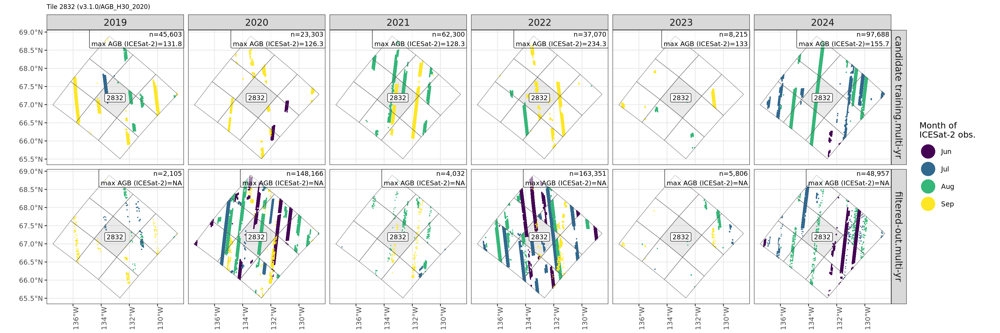

In [90]:
options(repr.plot.width = 18, repr.plot.height = 6, repr.plot.res = 200 , warn = -1 )

results_multiyr = GET_OBS_AND_COMBINE('s3://maap-ops-workspace/shared/montesano/DPS_tile_lists/BOREAL_MAP/v3.1.0/AGB_H30_2020/full_run_niter30_multiyear_atl08v6/AGB_tindex_master.csv', 2832, boreal_tiles, MODELLING_STRATEGY='multi-yr', BY_YEAR=TRUE)
results_multiyr[[2]]

### 1 tile example - multi-yr obs - collapse into 1 to sum up total n obs

🔍 Searching in bucket: maap-ops-workspace prefix: montesano/dps_output/run_boreal_biomass_map/v3.1.0/AGB_H30_2020/full_run_niter30_multiyear_atl08v6/2025/09/12/06/26/04/991266/ 
✅ Found 2 .parquet file(s):
    s3://maap-ops-workspace/montesano/dps_output/run_boreal_biomass_map/v3.1.0/AGB_H30_2020/full_run_niter30_multiyear_atl08v6/2025/09/12/06/26/04/991266/atl08_006_030m_2019_2024_06_09_filt_covars_merge_neighbors_002832.parquet 
    s3://maap-ops-workspace/montesano/dps_output/run_boreal_biomass_map/v3.1.0/AGB_H30_2020/full_run_niter30_multiyear_atl08v6/2025/09/12/06/26/04/991266/boreal_agb_2020_202509121757683152_0002832_train.parquet 
[1] "modelling_strategy" "obs_class"         


`summarise()` has grouped output by 'modelling_strategy'. You can override
using the `.groups` argument.


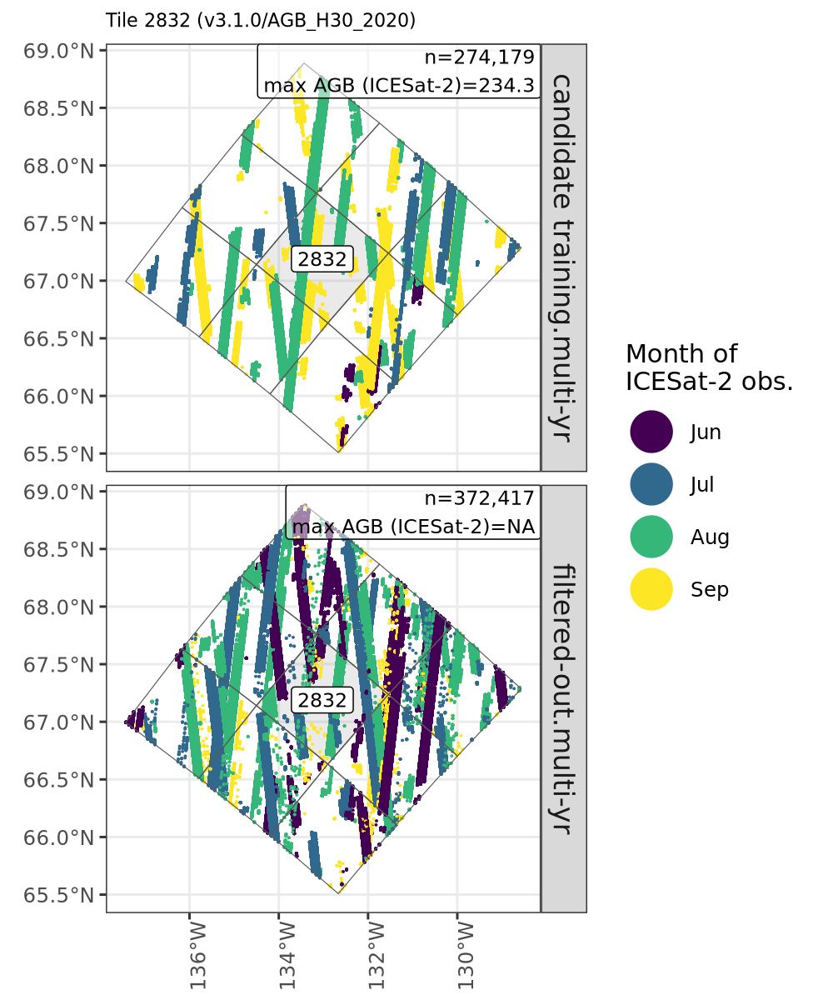

In [63]:
options(repr.plot.width = 5, repr.plot.height = 6, repr.plot.res = 200 , warn = -1 )

GET_OBS_AND_COMBINE('s3://maap-ops-workspace/shared/montesano/DPS_tile_lists/BOREAL_MAP/v3.1.0/AGB_H30_2020/full_run_niter30_multiyear_atl08v6/AGB_tindex_master.csv', 2832, boreal_tiles, MODELLING_STRATEGY='multi-yr', BY_YEAR=FALSE)

## Analyze sampling distribution between single yr and mult yr ICESat-2 for a given tile

In [174]:
library(deldir)
library(spatstat)

In [441]:
# # Usage
# s3_path_multiyr <- (AGB_multiyr_tindex %>% filter(tile_num == FOCAL_TILE))$s3_path
# parquet_files <- find_parquet_in_s3_dir(s3_path_multiyr)

# # Get the first parquet file
# if (!is.null(parquet_files) && length(parquet_files) > 0) {
#   mergeneighbors_parquet_multiyr <- parquet_files[1]
#   cat("Using:", mergeneighbors_parquet_multiyr, "\n")
#   multiyr_mergeneighbors <- st_read_parquet(mergeneighbors_parquet_multiyr) %>%
#             {st_crs(.) <- crs_canalb_fromraster; .} %>%
#             st_transform(crs=4326) %>% 
#             mutate(RH_98 = h_canopy) %>%
#             dplyr::select(RH_98, m, y, doy, geometry) %>% 
#             dplyr::mutate(
#                     AGB = NA,
#                     modelling_strategy = 'multi year',
#                     file_src = 'mergeneighbors'
#             ) %>%
#             dplyr::mutate(
#                 lon = st_coordinates(.)[,1],  
#                 lat = st_coordinates(.)[,2],
#                 lon_rnd = round(st_coordinates(.)[,1], 8),  # Round to 6 decimal places
#                 lat_rnd = round(st_coordinates(.)[,2], 8)
#                 ) %>% as.data.frame()

#   train_parquet_multiyr <- parquet_files[2]
#   cat("Using:", train_parquet_multiyr, "\n")
#   multiyr_train <- read_parquet(train_parquet_multiyr) %>%
#             dplyr::select(RH_98, AGB, lat, lon) %>% 
#             dplyr::mutate(
#                     y = NA,
#                     m = NA,
#                     doy = NA,
#                     modelling_strategy = 'multi year',
#                     file_src = 'train'
#             ) %>%
#             st_as_sf(coords = c("lon", "lat"), crs = 4326) %>%
#             dplyr::mutate(
#                 lon_rnd = round(st_coordinates(.)[,1], 8),  # Round to 6 decimal places
#                 lat_rnd = round(st_coordinates(.)[,2], 8)
#                 ) %>% as.data.frame()
# }
# # Combine the 2 pqrquet tables: merge neighbers and training
# #multiyr_gdf = rbind(gdf_multiyr_4326, df_multiyr_4326)
# multiyr_gdf = multiyr_mergeneighbors %>%
#             ## Join appoach 1
#             #st_join(multiyr_train %>% dplyr::select(RH_98, AGB, geometry) %>% mutate(geom2 = geometry), join = st_nearest_feature) %>%
#             # # Calculate actual distance to verify reasonable match
#             # dplyr::mutate(
#             #     match_distance = as.numeric(st_distance(geometry, geom2, by_element = TRUE))
#             # ) %>%
#             # dplyr::mutate(
#             #     # Identify the
#             #     # - training obs for which we have both RH_98 and AGB 
#             #     # - candidate obs (from mergeneighbors) do not have AGB; only when they are chosen for training is AGB computed before the rF modelling
#             #     obs_class = ifelse(match_distance <= 1, 'training obs.', 'candidate obs.'),  # 1m threshold
#             #     RH_98 = ifelse(match_distance <= 1, RH_98.y, RH_98.x)  ,
#             #     AGB = ifelse(match_distance <= 1, AGB.y, NA) 
#             # ) 
#             # Join approach 2
#             dplyr::left_join(multiyr_train, by = JOIN_COLS) %>%
#             dplyr::mutate(
#                 # Identify the
#                 # - training obs for which we have both RH_98 and AGB 
#                 # - candidate obs (from mergeneighbors) do not have AGB; only when they are chosen for training is AGB computed before the rF modelling
#                 file_src = ifelse((!is.na(file_src.x) & !is.na(file_src.y)), 'both', ifelse((!is.na(file_src.x) & is.na(file_src.y)),'mergeneighors', ifelse((is.na(file_src.x) & is.na(file_src.y)),'both NA','other case'))),
#                 obs_class = ifelse(!is.na(file_src.y), 'training obs.', 'candidate obs.'),
#                 RH_98 = ifelse(RH_98.y - RH_98.x <= 1, RH_98.x, NA)  , # get from larger set (merge neighbors)
#                 AGB = ifelse(RH_98.y - RH_98.x <= 1, AGB.y, NA)        # get from smaller set (training )
#             ) %>% 
#             st_as_sf(coords = c("lon", "lat"), crs = 4326)


## Quantifying sampling improvement for non-uniform ICESat-2 observations from those used for a multi-year model vs those used for a single year model
To quantify the improvement in sampling rigor between two point sets across a 270 km × 270 km tile with non-normally distributed vegetation height

#### Functions for spatial sampling analysis

In [171]:
analyze_points_in_tile_window <- function(points_sf, tiles_sf, lon_col="lon", lat_col="lat") {
  
  # Verify tiles_sf is in projected coordinates
  if(st_is_longlat(tiles_sf)) {
    stop("tiles_sf appears to be in geographic coordinates. Expected projected CRS.")
  }
  
  tiles_crs <- st_crs(tiles_sf)
  #message("Using tiles CRS: ", tiles_crs$input)
  
  # # Convert points to sf object (assuming they start in WGS84 lon/lat)
  # points_sf <- st_as_sf(points_df, coords = c(lon_col, lat_col), crs = 4326)
  
  # Transform points to match the tiles CRS
  points_proj <- st_transform(points_sf, st_crs(tiles_sf))
  
  # Create the analysis window - try multiple approaches
  tiles_union <- st_union(tiles_sf)
  
  # Method 1: Try to simplify the geometry first
  tiles_simplified <- st_simplify(tiles_union, dTolerance = 10)  # 10m tolerance
  
  # Method 2: Use bounding box if complex geometry conversion fails
  tiles_bbox <- st_bbox(tiles_union)
  
  # Try to create owin object
  window_tiles <- NULL
  window_method <- "unknown"
  
  tryCatch({
    # Attempt 1: Use simplified union
    tiles_sp <- as(tiles_simplified, "Spatial")
    window_tiles <- as.owin(tiles_sp)
    window_method <- "simplified_union"
    message("Successfully created window using simplified union")
  }, error = function(e) {
    message("Failed to create window from simplified union: ", e$message)
    
    tryCatch({
      # Attempt 2: Use original union
      tiles_sp <- as(tiles_union, "Spatial")
      window_tiles <- as.owin(tiles_sp)
      window_method <<- "original_union"
      message("Successfully created window using original union")
    }, error = function(e2) {
      message("Failed to create window from union: ", e2$message)
      
      # Attempt 3: Use bounding box as fallback
      window_tiles <<- owin(
        xrange = c(tiles_bbox$xmin, tiles_bbox$xmax),
        yrange = c(tiles_bbox$ymin, tiles_bbox$ymax)
      )
      window_method <<- "bounding_box"
      message("Using bounding box as window")
    })
  })
  
  if(is.null(window_tiles)) {
    stop("Failed to create analysis window from tiles")
  }
  
  # Filter points to only those within the tile window
  points_in_tiles <- st_intersection(points_proj, tiles_union)
  
  if(nrow(points_in_tiles) == 0) {
    stop("No points found within the tile window")
  }
  
  # Get coordinates of filtered points
  coords_filtered <- st_coordinates(points_in_tiles)
  
  # Ensure points are within the window bounds
  if(window_method == "bounding_box") {
    # For bounding box, points should already be within bounds
    # But let's double-check and filter if necessary
    in_bounds <- coords_filtered[,1] >= tiles_bbox$xmin & 
                coords_filtered[,1] <= tiles_bbox$xmax &
                coords_filtered[,2] >= tiles_bbox$ymin & 
                coords_filtered[,2] <= tiles_bbox$ymax
    
    coords_filtered <- coords_filtered[in_bounds, , drop = FALSE]
    points_in_tiles <- points_in_tiles[in_bounds, ]
  }
  
  if(nrow(coords_filtered) == 0) {
    stop("No points remain after filtering to window bounds")
  }
  
  # Create point pattern with the tile window
  ppp_obj <- ppp(coords_filtered[,1], coords_filtered[,2], window = window_tiles)
  
  # Calculate maximum radius for analysis (1/4 of minimum window dimension)
  if(window_method == "bounding_box") {
    window_dims <- c(
      tiles_bbox$xmax - tiles_bbox$xmin,
      tiles_bbox$ymax - tiles_bbox$ymin
    )
  } else {
    window_dims <- c(
      diff(range(coords_filtered[,1])), 
      diff(range(coords_filtered[,2]))
    )
  }
  
  r_max <- min(window_dims) / 4
  
  # Calculate L-function with appropriate edge correction
  L_func <- Lest(ppp_obj, rmax = r_max, correction = c("border"))
  
  # Additional metrics
  n_points <- nrow(coords_filtered)
  
  # Calculate area based on window method
  if(window_method == "bounding_box") {
    window_area <- (tiles_bbox$xmax - tiles_bbox$xmin) * (tiles_bbox$ymax - tiles_bbox$ymin)
  } else {
    window_area <- as.numeric(st_area(tiles_union))
  }
  
  density <- n_points / window_area
  
  return(list(
    ppp = ppp_obj,
    L_function = L_func,
    window = window_tiles,
    window_method = window_method,
    projected_coords = coords_filtered,
    n_points = n_points,
    density = as.numeric(density),
    window_area = as.numeric(window_area),
    r_max = r_max,
    points_sf = points_in_tiles,
    tiles_crs = tiles_crs,
    tiles_bbox = tiles_bbox
  ))
}

# Alternative simplified function that forces bounding box approach
analyze_points_bbox_window <- function(points_df, tiles_sf, lon_col="lon", lat_col="lat") {
  
  # Verify tiles_sf is in projected coordinates
  if(st_is_longlat(tiles_sf)) {
    stop("tiles_sf appears to be in geographic coordinates. Expected projected CRS.")
  }
  
  tiles_crs <- st_crs(tiles_sf)
  
  # Convert points to sf object and transform
  points_sf <- st_as_sf(points_df, coords = c(lon_col, lat_col), crs = 4326)
  points_proj <- st_transform(points_sf, st_crs(tiles_sf))
  
  # Use bounding box approach (more reliable)
  tiles_bbox <- st_bbox(tiles_sf)
  window_tiles <- owin(
    xrange = c(tiles_bbox$xmin, tiles_bbox$xmax),
    yrange = c(tiles_bbox$ymin, tiles_bbox$ymax)
  )
  
  # Filter points to bounding box
  coords <- st_coordinates(points_proj)
  in_bounds <- coords[,1] >= tiles_bbox$xmin & 
              coords[,1] <= tiles_bbox$xmax &
              coords[,2] >= tiles_bbox$ymin & 
              coords[,2] <= tiles_bbox$ymax
  
  coords_filtered <- coords[in_bounds, , drop = FALSE]
  points_filtered <- points_proj[in_bounds, ]
  
  if(nrow(coords_filtered) == 0) {
    stop("No points found within the tile bounding box")
  }
  
  # Create point pattern
  ppp_obj <- ppp(coords_filtered[,1], coords_filtered[,2], window = window_tiles)
  
  # Calculate analysis parameters
  window_dims <- c(
    tiles_bbox$xmax - tiles_bbox$xmin,
    tiles_bbox$ymax - tiles_bbox$ymin
  )
  r_max <- min(window_dims) / 4
  
  # Calculate L-function
  L_func <- Lest(ppp_obj, rmax = r_max, correction = c("border"))
  
  # Metrics
  n_points <- nrow(coords_filtered)
  window_area <- prod(window_dims)
  density <- n_points / window_area
  
  return(list(
    ppp = ppp_obj,
    L_function = L_func,
    window = window_tiles,
    window_method = "bounding_box",
    projected_coords = coords_filtered,
    n_points = n_points,
    density = as.numeric(density),
    window_area = as.numeric(window_area),
    r_max = r_max,
    points_sf = points_filtered,
    tiles_crs = tiles_crs,
    tiles_bbox = tiles_bbox
  ))
}

# Debug function to check your tiles geometry
debug_tiles_geometry <- function(tiles_sf) {
  cat("Tiles geometry information:\n")
  cat("- Number of tiles:", nrow(tiles_sf), "\n")
  cat("- CRS:", st_crs(tiles_sf)$input, "\n")
  cat("- Geometry type:", as.character(st_geometry_type(tiles_sf)), "\n")
  cat("- Is valid:", all(st_is_valid(tiles_sf)), "\n")
  cat("- Bounding box:\n")
  print(st_bbox(tiles_sf))
  
  # Check for complex geometries
  tiles_union <- st_union(tiles_sf)
  cat("- Union geometry type:", as.character(st_geometry_type(tiles_union)), "\n")
  cat("- Union is valid:", st_is_valid(tiles_union), "\n")
  
  # Try to convert to Spatial class
  tryCatch({
    tiles_sp <- as(tiles_union, "Spatial")
    cat("- Successfully converted to Spatial class\n")
    
    # Try to convert to owin
    tryCatch({
      window_test <- as.owin(tiles_sp)
      cat("- Successfully converted to owin\n")
    }, error = function(e) {
      cat("- Failed to convert to owin:", e$message, "\n")
    })
  }, error = function(e) {
    cat("- Failed to convert to Spatial class:", e$message, "\n")
  })
}

# Function to compare two point sets within the same tile window
compare_point_sets_in_tiles <- function(points_set1, points_set2, tiles_sf, 
                                       lon_col="lon", lat_col="lat") {
  
  # Analyze both point sets
  result1 <- analyze_points_in_tile_window(points_set1, tiles_sf, lon_col, lat_col)
  result2 <- analyze_points_in_tile_window(points_set2, tiles_sf, lon_col, lat_col)
  
  # Ensure both use the same window and r_max for fair comparison
  common_r_max <- min(result1$r_max, result2$r_max)
  
  # Recalculate L-functions with common parameters
  L1 <- Lest(result1$ppp, rmax = common_r_max, correction = c("border"))
  L2 <- Lest(result2$ppp, rmax = common_r_max, correction = c("border"))
  
  # Calculate summary statistics - ensure all vectors have same length
  metrics <- c("Number of points", "Point density (per km²)", "Window area (km²)")
  
  set1_values <- c(
    result1$n_points, 
    result1$density * 1e6,  # Convert to per km²
    result1$window_area / 1e6  # Convert to km²
  )
  
  set2_values <- c(
    result2$n_points, 
    result2$density * 1e6, 
    result2$window_area / 1e6
  )
  
  # Create comparison dataframe
  comparison <- data.frame(
    metric = metrics,
    set1 = set1_values,
    set2 = set2_values,
    stringsAsFactors = FALSE
  )
  
  # Calculate improvement percentage
  comparison$improvement_pct <- 100 * (comparison$set2 - comparison$set1) / comparison$set1
  
  # Add some additional comparison metrics
  additional_metrics <- data.frame(
    metric = c("Point density ratio (set2/set1)", "Additional points in set2"),
    set1 = c(NA, NA),  # These don't apply to set1
    set2 = c(
      result2$density / result1$density,
      result2$n_points - result1$n_points
    ),
    improvement_pct = c(
      100 * (result2$density / result1$density - 1),
      NA  # Not applicable for absolute difference
    ),
    stringsAsFactors = FALSE
  )
  
  # Combine all metrics
  comparison_full <- rbind(comparison, additional_metrics)
  
  return(list(
    result1 = result1,
    result2 = result2,
    L1 = L1,
    L2 = L2,
    comparison = comparison_full,
    common_r_max = common_r_max,
    summary = list(
      set1_points = result1$n_points,
      set2_points = result2$n_points,
      density_improvement = result2$density / result1$density,
      additional_points = result2$n_points - result1$n_points
    )
  ))
}

# Alternative simpler version that avoids the error
compare_point_sets_simple <- function(points_set1, points_set2, tiles_sf, 
                                     lon_col="lon", lat_col="lat") {
  
  # Analyze both point sets
  result1 <- analyze_points_in_tile_window(points_set1, tiles_sf, lon_col, lat_col)
  result2 <- analyze_points_in_tile_window(points_set2, tiles_sf, lon_col, lat_col)
  
  # Print basic comparison
  cat("=== Point Set Comparison ===\n")
  cat("Set 1 - Points:", result1$n_points, "\n")
  cat("Set 2 - Points:", result2$n_points, "\n")
  cat("Difference:", result2$n_points - result1$n_points, "\n")
  cat("Set 1 - Density:", round(result1$density * 1e6, 4), "points/km²\n")
  cat("Set 2 - Density:", round(result2$density * 1e6, 4), "points/km²\n")
  cat("Density ratio (set2/set1):", round(result2$density / result1$density, 3), "\n")
  cat("Window area:", round(result1$window_area / 1e6, 2), "km²\n")
  
  # Ensure both use the same window and r_max for fair comparison
  common_r_max <- min(result1$r_max, result2$r_max)
  
  # Recalculate L-functions with common parameters
  L1 <- Lest(result1$ppp, rmax = common_r_max, correction = c("border"))
  L2 <- Lest(result2$ppp, rmax = common_r_max, correction = c("border"))
  
  # Create simple comparison data frame
  comparison_df <- data.frame(
    Metric = c("Number of points", "Density (points/km²)", "Window area (km²)"),
    Set_1 = c(result1$n_points, 
              round(result1$density * 1e6, 4), 
              round(result1$window_area / 1e6, 2)),
    Set_2 = c(result2$n_points, 
              round(result2$density * 1e6, 4), 
              round(result2$window_area / 1e6, 2))
  )
  
  comparison_df$Improvement_pct <- round(100 * (comparison_df$Set_2 - comparison_df$Set_1) / comparison_df$Set_1, 2)
  
  return(list(
    result1 = result1,
    result2 = result2,
    L1 = L1,
    L2 = L2,
    comparison = comparison_df,
    common_r_max = common_r_max
  ))
}

# # Usage example with error checking:
# tryCatch({
#   comparison_result <- compare_point_sets_in_tiles(points_set1, points_set2, tiles_sf)
#   print(comparison_result$comparison)
# }, error = function(e) {
#   cat("Error in main function:", e$message, "\n")
#   cat("Trying simplified version...\n")
#   comparison_result <- compare_point_sets_simple(points_set1, points_set2, tiles_sf)
#   print(comparison_result$comparison)
# })

# Visualization function
plot_points_and_tiles <- function(analysis_result, tiles_sf, title = "Point Pattern Analysis") {
  
  # Convert spatstat window back to sf for plotting
  points_in_analysis <- analysis_result$points_sf
  
  # Create the plot
  ggplot() +
    geom_sf(data = tiles_sf, fill = "lightgray", color = "black", alpha = 0.3) +
    geom_sf(data = points_in_analysis, color = "black", size = 0.25, alpha = 0.7) +
    theme_minimal() +
    labs(title = title,
         subtitle = paste("n =", analysis_result$n_points, "30m ICESat-2 candidate training obs."),
         caption = paste("Density:", round(analysis_result$density * 1e6, 2), "obs./km²")) +
    theme(axis.text = element_text(size = 8))
}

#Plot L-functions
plot_l_functions <- function(comparison_result) {
  plot(comparison_result$L1, main = "L-function Comparison", 
       xlim = c(0, comparison_result$common_r_max))
  plot(comparison_result$L2, add = TRUE, col = "red")
  legend("bottomright", c("Set 1", "Set 2"), col = c("black", "red"), lty = 1)
}

plot_l_functions_ggplot <- function(comparison_result, 
                                   set1_name = "Set 1 (fewer points)", 
                                   set2_name = "Set 2 (more points)") {
  
  # Extract L-function data
  L1 <- comparison_result$L1
  L2 <- comparison_result$L2
  common_r_max <- comparison_result$common_r_max
  
  # Create combined data frame for plotting
  l_data <- data.frame(
    r = c(L1$r, L2$r),
    L_border = c(L1$border, L2$border),
    Set = c(rep(set1_name, length(L1$r)), 
            rep(set2_name, length(L2$r)))
  ) %>%
    filter(r <= common_r_max)  # Filter to common range
  
  # Create the plot
  p <- ggplot(l_data, aes(x = r, y = L_border, color = Set)) +
    geom_line(size = 1.2, alpha = 0.8) +
    geom_hline(yintercept = 0, linetype = "dashed", color = "gray50", size = 0.8) +
    scale_color_manual(values = c("blue", "red")) +
    labs(
      title = "L-Function Comparison: Spatial Point Patterns",
      subtitle = "Deviation from Complete Spatial Randomness",
      x = "Distance (meters)",
      y = "L(r) - r",
      color = "Point Set",
      caption = "L > 0: Clustered | L = 0: Random | L < 0: Regular/Dispersed"
    ) +
    theme_minimal() +
    theme(
      plot.title = element_text(size = 14, face = "bold"),
      plot.subtitle = element_text(size = 12, color = "gray40"),
      legend.position = "bottom",
      panel.grid.minor = element_blank(),
      plot.caption = element_text(size = 10, color = "gray50")
    ) +
    guides(color = guide_legend(override.aes = list(size = 2)))
  
  # Add interpretation annotations
  avg_L1 <- mean(L1$border[L1$r <= common_r_max], na.rm = TRUE)
  avg_L2 <- mean(L2$border[L2$r <= common_r_max], na.rm = TRUE)
  
  # Add text annotations for interpretation
  y_range <- range(l_data$L_border, na.rm = TRUE)
  y_pos <- y_range[2] - 0.1 * diff(y_range)
  
  annotation_text <- paste0(
    "Avg L-values: ",
    set1_name, " = ", round(avg_L1, 0), "m | ",
    set2_name, " = ", round(avg_L2, 0), "m"
  )
  
  p <- p + annotate("text", x = common_r_max * 0.05, y = y_pos, 
                   label = annotation_text, 
                   hjust = 0, size = 3.5, color = "gray30")
  
  return(p)
}

# Enhanced version with faceted subplots for detailed analysis
plot_l_functions_detailed <- function(comparison_result,
                                     set1_name = "Set 1 (fewer points)", 
                                     set2_name = "Set 2 (more points)") {
  
  L1 <- comparison_result$L1
  L2 <- comparison_result$L2
  common_r_max <- comparison_result$common_r_max
  
  # # Debug: Check the structure of L-function objects
  # cat("L1 structure:\n")
  # print(str(L1))
  # cat("L2 structure:\n")
  # print(str(L2))
  # cat("L1 names:", names(L1), "\n")
  # cat("L2 names:", names(L2), "\n")
  # cat("L1 length:", length(L1$r), "\n")
  # cat("L2 length:", length(L2$r), "\n")
  
  # Check if required columns exist
  if(!"border" %in% names(L1)) {
    stop("L1 object missing 'border' column. Available columns: ", paste(names(L1), collapse = ", "))
  }
  if(!"border" %in% names(L2)) {
    stop("L2 object missing 'border' column. Available columns: ", paste(names(L2), collapse = ", "))
  }
  
  # Check for empty objects
  if(length(L1$r) == 0 || length(L2$r) == 0) {
    stop("One of the L-function objects is empty")
  }
  
  # Use only columns that exist in both objects
  available_corrections <- intersect(names(L1), names(L2))
  available_corrections <- available_corrections[!available_corrections %in% c("r", "theo")]
  
  cat("Available corrections:", paste(available_corrections, collapse = ", "), "\n")
  
  # Use the first available correction method
  correction_method <- if("border" %in% available_corrections) {
    "border"
  } else if("iso" %in% available_corrections) {
    "iso"
  } else {
    available_corrections[1]
  }
  
  cat("Using correction method:", correction_method, "\n")
  
  # Create combined data frame with error checking
  tryCatch({
    l_data <- data.frame(
      r = c(L1$r, L2$r),
      L_value = c(L1[[correction_method]], L2[[correction_method]]),
      Set = c(rep(set1_name, length(L1$r)), 
              rep(set2_name, length(L2$r)))
    ) %>%
      filter(r <= common_r_max, !is.na(L_value)) %>%
      mutate(
        r_km = r / 1000,  # Convert to km for easier reading
        Scale = case_when(
          r <= common_r_max/3 ~ "Short range",
          r <= 2*common_r_max/3 ~ "Medium range",
          TRUE ~ "Long range"
        )
      )
  }, error = function(e) {
    stop("Error creating data frame: ", e$message)
  })
  
  if(nrow(l_data) == 0) {
    stop("No data remaining after filtering")
  }
  
  cat("Created data frame with", nrow(l_data), "rows\n")
  
  # Main comparison plot
  p1 <- ggplot(l_data, aes(x = r_km, y = L_value, color = Set)) +
    geom_line(size = 1.2, alpha = 0.8) +
    geom_hline(yintercept = 0, linetype = "dashed", color = "gray50") +
    scale_color_manual(values = c("blue", "red")) +
    labs(
      title = "L-Function Comparison",
      x = "Distance (km)",
      y = paste("L(r) - r (meters) [", correction_method, " correction]"),
      color = "Point Set"
    ) +
    theme_minimal() +
    theme(legend.position = "bottom")
  
  # Create difference plot
  tryCatch({
    # Ensure both sets have the same r values for comparison
    l1_data <- l_data %>% filter(Set == set1_name)
    l2_data <- l_data %>% filter(Set == set2_name)
    
    # Find common r values
    common_r <- intersect(l1_data$r, l2_data$r)
    
    if(length(common_r) == 0) {
      warning("No common r values found between sets. Using interpolation.")
      # Use the set with fewer points as reference
      if(nrow(l1_data) <= nrow(l2_data)) {
        reference_r <- l1_data$r
        l2_interp <- approx(l2_data$r, l2_data$L_value, xout = reference_r)$y
        l_diff <- data.frame(
          r = reference_r,
          r_km = reference_r / 1000,
          L_difference = l2_interp - l1_data$L_value
        )
      } else {
        reference_r <- l2_data$r
        l1_interp <- approx(l1_data$r, l1_data$L_value, xout = reference_r)$y
        l_diff <- data.frame(
          r = reference_r,
          r_km = reference_r / 1000,
          L_difference = l2_data$L_value - l1_interp
        )
      }
    } else {
      # Use exact matches
      l1_common <- l1_data %>% filter(r %in% common_r) %>% arrange(r)
      l2_common <- l2_data %>% filter(r %in% common_r) %>% arrange(r)
      
      l_diff <- data.frame(
        r = l1_common$r,
        r_km = l1_common$r_km,
        L_difference = l2_common$L_value - l1_common$L_value
      )
    }
    
    # Remove any NA values
    l_diff <- l_diff %>% filter(!is.na(L_difference))
    
    p2 <- ggplot(l_diff, aes(x = r_km, y = L_difference)) +
      geom_line(size = 1, color = "purple") +
      geom_hline(yintercept = 0, linetype = "dashed", color = "gray50") +
      geom_ribbon(aes(ymin = pmin(L_difference, 0), ymax = 0), 
                  alpha = 0.3, fill = "blue") +
      geom_ribbon(aes(ymin = 0, ymax = pmax(L_difference, 0)), 
                  alpha = 0.3, fill = "red") +
      labs(
        title = "Difference in L-Functions",
        subtitle = paste("Positive =", set2_name, "more clustered"),
        x = "Distance (km)",
        y = paste("L(", set2_name, ") - L(", set1_name, ")")
      ) +
      theme_minimal()
    
  }, error = function(e) {
    warning("Could not create difference plot: ", e$message)
    p2 <- ggplot() + 
      annotate("text", x = 0.5, y = 0.5, label = "Difference plot unavailable") +
      theme_void()
  })
  
  # Try to combine plots if patchwork is available
  if(requireNamespace("patchwork", quietly = TRUE)) {
    combined_plot <- p1 / p2 + 
      patchwork::plot_layout(heights = c(2, 1)) +
      patchwork::plot_annotation(
        title = "Spatial Point Pattern Analysis",
        caption = "L > 0: Clustered | L = 0: Random | L < 0: Regular/Dispersed"
      )
  } else {
    combined_plot <- NULL
    message("Install 'patchwork' package for combined plots")
  }
  
  return(list(
    main_plot = p1,
    difference_plot = p2,
    combined_plot = combined_plot,
    data = l_data,
    correction_used = correction_method
  ))
}

# Simplified robust version
plot_l_functions_simple <- function(comparison_result,
                                   set1_name = "Set 1 (fewer points)", 
                                   set2_name = "Set 2 (more points)") {
  
  L1 <- comparison_result$L1
  L2 <- comparison_result$L2
  common_r_max <- comparison_result$common_r_max
  
  # Find available correction method
  correction_method <- if("border" %in% names(L1) && "border" %in% names(L2)) {
    "border"
  } else if("iso" %in% names(L1) && "iso" %in% names(L2)) {
    "iso"
  } else {
    # Find first common correction method
    common_methods <- intersect(names(L1), names(L2))
    common_methods <- common_methods[!common_methods %in% c("r", "theo")]
    if(length(common_methods) > 0) {
      common_methods[1]
    } else {
      stop("No common correction methods found between L1 and L2")
    }
  }
  
  # Create data frame
  l_data <- data.frame(
    Distance_km = c(L1$r / 1000, L2$r / 1000),
    L_function = c(L1[[correction_method]], L2[[correction_method]]),
    Point_Set = factor(c(rep(set1_name, length(L1$r)), 
                        rep(set2_name, length(L2$r))))
  ) %>%
    filter(Distance_km <= common_r_max / 1000, !is.na(L_function))
  
  # Create plot
  p <- ggplot(l_data, aes(x = Distance_km, y = L_function, color = Point_Set)) +
    geom_line(size = 1.2, alpha = 0.8) +
    geom_hline(yintercept = 0, linetype = "dashed", color = "gray50", size = 0.8) +
    scale_color_manual(values = c("blue", "red")) +
    labs(
      title = "L-Function Comparison: Spatial Point Patterns",
      subtitle = paste("Using", correction_method, "edge correction"),
      x = "Distance (km)",
      y = "L(r) - r (meters)",
      color = "Point Set",
      caption = "L > 0: Clustered | L = 0: Random | L < 0: Regular/Dispersed"
    ) +
    theme_minimal() +
    theme(
      plot.title = element_text(size = 14, face = "bold"),
      plot.subtitle = element_text(size = 12, color = "gray40"),
      legend.position = "bottom",
      panel.grid.minor = element_blank(),
      plot.caption = element_text(size = 10, color = "gray50")
    )
  
  return(list(plot = p, data = l_data, correction_used = correction_method))
}

# Usage with error handling:
plot_l_with_fallback <- function(comparison_result, ...) {
  tryCatch({
    result <- plot_l_functions_detailed(comparison_result, ...)
    return(result)
  }, error = function(e) {
    warning("Detailed plot failed: ", e$message, "\nFalling back to simple plot.")
    result <- plot_l_functions_simple(comparison_result, ...)
    return(result)
  })
}

# Function to create interpretation summary
interpret_l_functions <- function(comparison_result,
                                 set1_name = "Set 1", 
                                 set2_name = "Set 2") {
  
  L1 <- comparison_result$L1
  L2 <- comparison_result$L2
  common_r_max <- comparison_result$common_r_max
  
  # Calculate summary statistics
  valid_range <- L1$r <= common_r_max
  avg_L1 <- mean(L1$border[valid_range], na.rm = TRUE)
  avg_L2 <- mean(L2$border[valid_range], na.rm = TRUE)
  max_L1 <- max(L1$border[valid_range], na.rm = TRUE)
  max_L2 <- max(L2$border[valid_range], na.rm = TRUE)
  
  # Create interpretation text
  interpretation <- data.frame(
    Metric = c("Average L-value", "Maximum L-value", "Pattern type", "Spatial quality"),
    Set_1 = c(
      paste(round(avg_L1, 0), "m"),
      paste(round(max_L1, 0), "m"),
      ifelse(abs(avg_L1) < 100, "Nearly random", 
             ifelse(avg_L1 > 100, "Clustered", "Regular")),
      ifelse(abs(avg_L1) < abs(avg_L2), "Better", "Worse")
    ),
    Set_2 = c(
      paste(round(avg_L2, 0), "m"),
      paste(round(max_L2, 0), "m"),
      ifelse(abs(avg_L2) < 100, "Nearly random", 
             ifelse(avg_L2 > 100, "Clustered", "Regular")),
      ifelse(abs(avg_L2) < abs(avg_L1), "Better", "Worse")
    )
  )
  
  # Print interpretation
  cat("\n=== L-Function Interpretation ===\n")
  print(interpretation, row.names = FALSE)
  
  if(abs(avg_L2) < abs(avg_L1)) {
    improvement <- (abs(avg_L1) - abs(avg_L2)) / abs(avg_L1) * 100
    cat("\n*** ", set2_name, " shows better spatial distribution ***\n")
    cat("Improvement in spatial randomness:", round(improvement, 1), "%\n")
  } else if(abs(avg_L1) < abs(avg_L2)) {
    cat("\n*** ", set1_name, " shows better spatial distribution ***\n")
  } else {
    cat("\n*** Both sets show similar spatial distribution ***\n")
  }
  
  return(interpretation)
}

#### Put it all together

In [189]:
head(results_singleyr[[1]] %>% filter(obs_class == 'candidate training', file_src == 'both'))

,lon_rnd,lat_rnd,file_src,obs_class,RH_98,AGB,tile_num,y,doy,modelling_strategy,date,month,geometry
,<dbl>,<dbl>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<int>,<int>,<chr>,<date>,<ord>,<POINT [°]>
1,-154.7135,68.68007,both,candidate training,0.4140930,0.7098717,3173,2020,157,1 yr,2020-06-05,Jun,POINT (-154.7135 68.68007)
2,-154.7136,68.67980,both,candidate training,0.6929626,1.0295518,3173,2020,157,1 yr,2020-06-05,Jun,POINT (-154.7136 68.6798)
3,-154.7136,68.67953,both,candidate training,0.6189575,0.9389855,3173,2020,157,1 yr,2020-06-05,Jun,POINT (-154.7136 68.67953)
4,-154.7203,68.65977,both,candidate training,1.5631714,1.6032080,3173,2020,157,1 yr,2020-06-05,Jun,POINT (-154.7203 68.65977)
5,-154.7204,68.65950,both,candidate training,0.0000000,0.3439852,3173,2020,157,1 yr,2020-06-05,Jun,POINT (-154.7204 68.6595)
6,-154.7205,68.65923,both,candidate training,0.0000000,0.3439852,3173,2020,157,1 yr,2020-06-05,Jun,POINT (-154.7205 68.65923)


                           metric         set1         set2 improvement_pct
1                Number of points 95258.000000 1.571350e+05        64.95727
2         Point density (per km²)     1.306694 2.155487e+00        64.95727
3               Window area (km²) 72900.000000 7.290000e+04         0.00000
4 Point density ratio (set2/set1)           NA 1.649573e+00        64.95727
5       Additional points in set2           NA 6.187700e+04              NA

=== L-Function Interpretation ===
          Metric     Set_1     Set_2
 Average L-value   42753 m   43829 m
 Maximum L-value   72993 m   82546 m
    Pattern type Clustered Clustered
 Spatial quality    Better     Worse

***  Set 1  shows better spatial distribution ***
Available corrections: border 
Using correction method: border 
Created data frame with 1026 rows


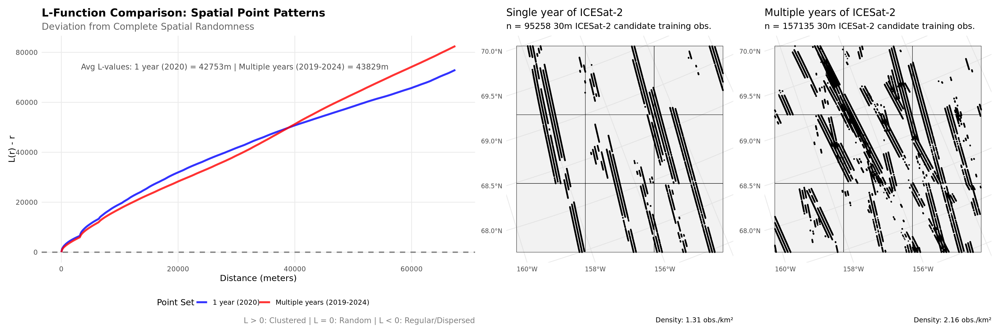

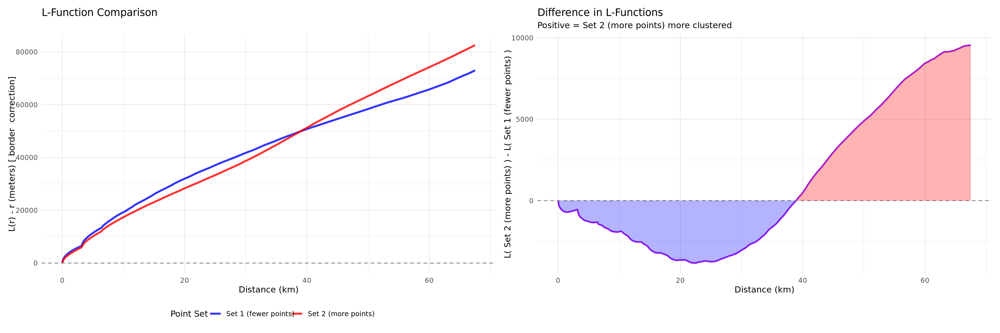

In [176]:
options(repr.plot.width = 18, repr.plot.height = 6, repr.plot.res = 200 , warn = -1 )

FOCAL_TILE = 3173

results_singleyr = GET_OBS_AND_COMBINE('s3://maap-ops-workspace/shared/montesano/DPS_tile_lists/BOREAL_MAP/v3.1.0/AGB_H30_2020/full_run/AGB_tindex_master.csv', FOCAL_TILE, boreal_tiles, MODELLING_STRATEGY='1 yr', BY_YEAR=TRUE)
results_multiyr = GET_OBS_AND_COMBINE('s3://maap-ops-workspace/shared/montesano/DPS_tile_lists/BOREAL_MAP/v3.1.0/AGB_H30_2020/full_run_niter30_multiyear_atl08v6/AGB_tindex_master.csv', FOCAL_TILE, boreal_tiles, MODELLING_STRATEGY='multi-yr', BY_YEAR=TRUE)

boreal_tiles_focal = SUBSET_3x3_TILES_WINDOW(boreal_tiles, FOCAL_TILE)

df_tile_single_yr = results_singleyr[[1]] %>% 
        filter(obs_class == 'candidate training', y == 2020) %>%
        st_transform(crs=crs_canalb_fromraster) %>%
        dplyr::mutate(
                    xgeo = st_coordinates(.)[,1],  
                    ygeo = st_coordinates(.)[,2],
            )

df_tile_multi_yr = results_multiyr[[1]] %>% 
        filter(obs_class == 'candidate training') %>%
        st_transform(crs=crs_canalb_fromraster) %>%
        dplyr::mutate(
                    xgeo = st_coordinates(.)[,1],  
                    ygeo = st_coordinates(.)[,2],
            )

# Load your data
tiles_3x3 <- boreal_tiles_focal %>% st_transform(crs=crs_canalb_fromraster)

#Perform the comparison
comparison_result <- compare_point_sets_in_tiles(df_tile_single_yr, df_tile_multi_yr, tiles_3x3, lon_col="lon_rnd", lat_col="lat_rnd")

#View comparison metrics
print(comparison_result$comparison)

interpretation <- interpret_l_functions(comparison_result)

plot_L = plot_l_functions_ggplot(comparison_result, 
                                   set1_name = "1 year (2020)", 
                                   set2_name = "Multiple years (2019-2024)")
m_p1 = plot_points_and_tiles(comparison_result$result1, tiles_3x3, "Single year of ICESat-2")
m_p2 = plot_points_and_tiles(comparison_result$result2, tiles_3x3, "Multiple years of ICESat-2")

plot_L | m_p1 | m_p2

# Detailed version with difference plot
p_detailed <- plot_l_functions_detailed(comparison_result)
p_detailed$main_plot | p_detailed$difference_plot

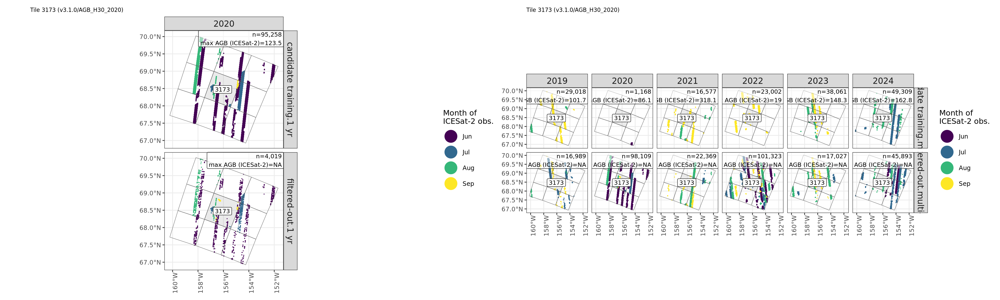

In [180]:
options(repr.plot.width = 20, repr.plot.height = 6, repr.plot.res = 200 , warn = -1 )

results_singleyr[[2]] | results_multiyr[[2]]

## Other examples

🔍 Searching in bucket: maap-ops-workspace prefix: aliz237/dps_output/run_boreal_biomass_map/v3.2.0/AGB_H30_2020/full_run/2025/10/13/07/01/58/528134/ 
✅ Found 2 .parquet file(s):
    s3://maap-ops-workspace/aliz237/dps_output/run_boreal_biomass_map/v3.2.0/AGB_H30_2020/full_run/2025/10/13/07/01/58/528134/atl08_006_030m_2020_2020_06_09_filt_covars_merge_neighbors_037522.parquet 
    s3://maap-ops-workspace/aliz237/dps_output/run_boreal_biomass_map/v3.2.0/AGB_H30_2020/full_run/2025/10/13/07/01/58/528134/boreal_agb_2020_202510131760336087_0037522_train.parquet 
[1] "modelling_strategy" "obs_class"         


`summarise()` has grouped output by 'modelling_strategy'. You can override
using the `.groups` argument.


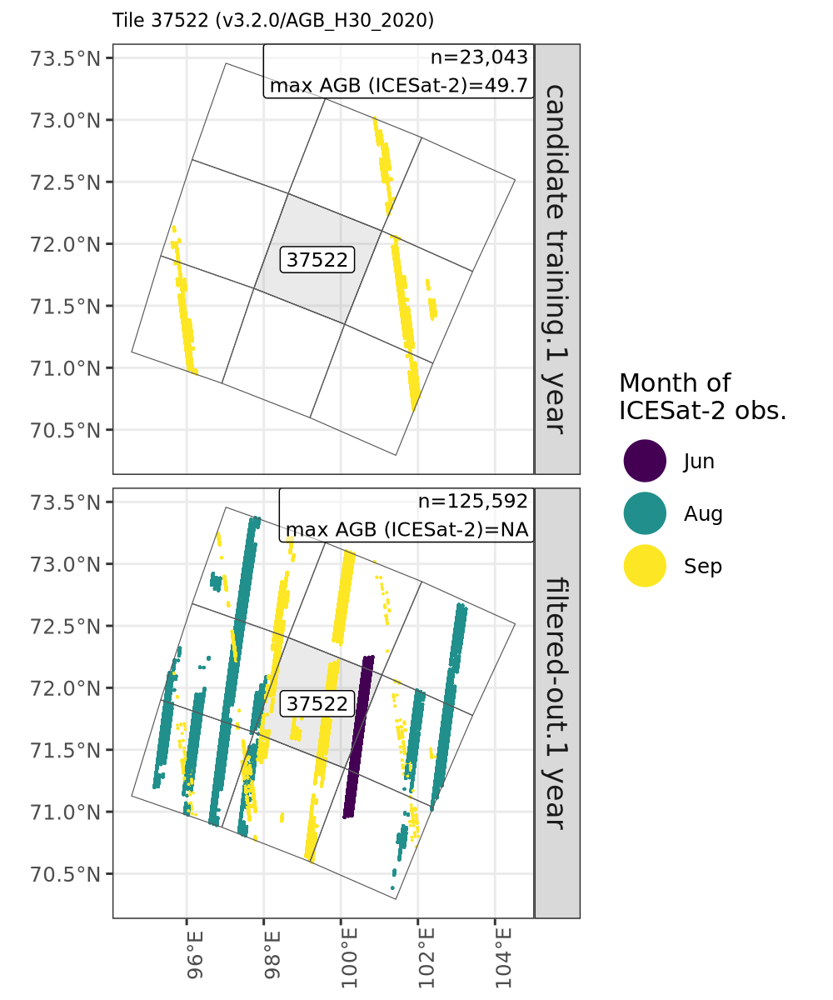

In [191]:
options(repr.plot.width = 5, repr.plot.height = 6, repr.plot.res = 200 , warn = -1 )

GET_OBS_AND_COMBINE('s3://maap-ops-workspace/shared/montesano/DPS_tile_lists/BOREAL_MAP/v3.2.0/AGB_H30_2020/full_run/AGB_tindex_master.csv', 37522, boreal_tiles, MODELLING_STRATEGY='1 year', BY_YEAR = FALSE)[[2]]

## Many plots going North to South

🔍 Searching in bucket: maap-ops-workspace prefix: aliz237/dps_output/run_boreal_biomass_map/v3.2.0/AGB_H30_2020/full_run/2025/10/13/07/01/58/528134/ 
✅ Found 2 .parquet file(s):
    s3://maap-ops-workspace/aliz237/dps_output/run_boreal_biomass_map/v3.2.0/AGB_H30_2020/full_run/2025/10/13/07/01/58/528134/atl08_006_030m_2020_2020_06_09_filt_covars_merge_neighbors_037522.parquet 
    s3://maap-ops-workspace/aliz237/dps_output/run_boreal_biomass_map/v3.2.0/AGB_H30_2020/full_run/2025/10/13/07/01/58/528134/boreal_agb_2020_202510131760336087_0037522_train.parquet 
[1] "modelling_strategy" "obs_class"          "y"                 


`summarise()` has grouped output by 'modelling_strategy', 'obs_class'. You can
override using the `.groups` argument.


🔍 Searching in bucket: maap-ops-workspace prefix: aliz237/dps_output/run_boreal_biomass_map/v3.2.0/AGB_H30_2020/full_run/2025/10/13/04/32/01/370908/ 
✅ Found 2 .parquet file(s):
    s3://maap-ops-workspace/aliz237/dps_output/run_boreal_biomass_map/v3.2.0/AGB_H30_2020/full_run/2025/10/13/04/32/01/370908/atl08_006_030m_2020_2020_06_09_filt_covars_merge_neighbors_001775.parquet 
    s3://maap-ops-workspace/aliz237/dps_output/run_boreal_biomass_map/v3.2.0/AGB_H30_2020/full_run/2025/10/13/04/32/01/370908/boreal_agb_2020_202510131760327136_0001775_train.parquet 
[1] "modelling_strategy" "obs_class"          "y"                 


`summarise()` has grouped output by 'modelling_strategy', 'obs_class'. You can
override using the `.groups` argument.


🔍 Searching in bucket: maap-ops-workspace prefix: aliz237/dps_output/run_boreal_biomass_map/v3.2.0/AGB_H30_2020/full_run/2025/10/13/04/54/13/725307/ 
✅ Found 2 .parquet file(s):
    s3://maap-ops-workspace/aliz237/dps_output/run_boreal_biomass_map/v3.2.0/AGB_H30_2020/full_run/2025/10/13/04/54/13/725307/atl08_006_030m_2020_2020_06_09_filt_covars_merge_neighbors_001902.parquet 
    s3://maap-ops-workspace/aliz237/dps_output/run_boreal_biomass_map/v3.2.0/AGB_H30_2020/full_run/2025/10/13/04/54/13/725307/boreal_agb_2020_202510131760328491_0001902_train.parquet 
[1] "modelling_strategy" "obs_class"          "y"                 


`summarise()` has grouped output by 'modelling_strategy', 'obs_class'. You can
override using the `.groups` argument.


🔍 Searching in bucket: maap-ops-workspace prefix: aliz237/dps_output/run_boreal_biomass_map/v3.2.0/AGB_H30_2020/full_run/2025/10/13/04/55/19/977202/ 
✅ Found 2 .parquet file(s):
    s3://maap-ops-workspace/aliz237/dps_output/run_boreal_biomass_map/v3.2.0/AGB_H30_2020/full_run/2025/10/13/04/55/19/977202/atl08_006_030m_2020_2020_06_09_filt_covars_merge_neighbors_001822.parquet 
    s3://maap-ops-workspace/aliz237/dps_output/run_boreal_biomass_map/v3.2.0/AGB_H30_2020/full_run/2025/10/13/04/55/19/977202/boreal_agb_2020_202510131760327586_0001822_train.parquet 
[1] "modelling_strategy" "obs_class"          "y"                 


`summarise()` has grouped output by 'modelling_strategy', 'obs_class'. You can
override using the `.groups` argument.


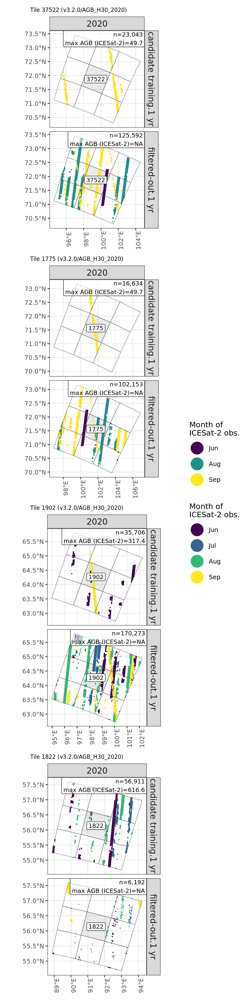

In [65]:
options(repr.plot.width = 5, repr.plot.height = 20, repr.plot.res = 200 , warn = -1 )
AGB_TINDEX_FN = 's3://maap-ops-workspace/shared/montesano/DPS_tile_lists/BOREAL_MAP/v3.2.0/AGB_H30_2020/full_run/AGB_tindex_master.csv'
(
GET_OBS_AND_COMBINE(AGB_TINDEX_FN, 37522, boreal_tiles, MODELLING_STRATEGY='1 yr') /
GET_OBS_AND_COMBINE(AGB_TINDEX_FN, 1775, boreal_tiles, MODELLING_STRATEGY='1 yr') /
GET_OBS_AND_COMBINE(AGB_TINDEX_FN, 1902, boreal_tiles, MODELLING_STRATEGY='1 yr') /
GET_OBS_AND_COMBINE(AGB_TINDEX_FN, 1822, boreal_tiles, MODELLING_STRATEGY='1 yr') 
    ) + plot_layout(guides = 'collect')

An AGB model that uses ICESat-2 from a single year will be subset to the limited sampling  of that single year. In 2020, this sampling resulted in many daytime obs which were removed with a filter. For the higher latitudes, this was more consequential as the growing season is more likely to be observed during the much longer daytime period (polar summer). 

#### Look at the multi-yr (2019-2024) training obs that go into any target year's AGB modelling

🔍 Searching in bucket: maap-ops-workspace prefix: montesano/dps_output/run_boreal_biomass_map/v3.1.0/AGB_H30_2022/full_run_niter30_multiyear_atl08v6/2025/09/23/15/09/40/576921/ 
✅ Found 2 .parquet file(s):
    s3://maap-ops-workspace/montesano/dps_output/run_boreal_biomass_map/v3.1.0/AGB_H30_2022/full_run_niter30_multiyear_atl08v6/2025/09/23/15/09/40/576921/atl08_006_030m_2019_2024_06_09_filt_covars_merge_neighbors_037522.parquet 
    s3://maap-ops-workspace/montesano/dps_output/run_boreal_biomass_map/v3.1.0/AGB_H30_2022/full_run_niter30_multiyear_atl08v6/2025/09/23/15/09/40/576921/boreal_agb_2022_202509231758664885_0037522_train.parquet 
[1] "modelling_strategy" "obs_class"          "y"                 


`summarise()` has grouped output by 'modelling_strategy', 'obs_class'. You can
override using the `.groups` argument.


🔍 Searching in bucket: maap-ops-workspace prefix: montesano/dps_output/run_boreal_biomass_map/v3.1.0/AGB_H30_2022/full_run_niter30_multiyear_atl08v6/2025/09/11/17/09/53/228975/ 
✅ Found 2 .parquet file(s):
    s3://maap-ops-workspace/montesano/dps_output/run_boreal_biomass_map/v3.1.0/AGB_H30_2022/full_run_niter30_multiyear_atl08v6/2025/09/11/17/09/53/228975/atl08_006_030m_2019_2024_06_09_filt_covars_merge_neighbors_001775.parquet 
    s3://maap-ops-workspace/montesano/dps_output/run_boreal_biomass_map/v3.1.0/AGB_H30_2022/full_run_niter30_multiyear_atl08v6/2025/09/11/17/09/53/228975/boreal_agb_2022_202509111757635428_0001775_train.parquet 
[1] "modelling_strategy" "obs_class"          "y"                 


`summarise()` has grouped output by 'modelling_strategy', 'obs_class'. You can
override using the `.groups` argument.


🔍 Searching in bucket: maap-ops-workspace prefix: montesano/dps_output/run_boreal_biomass_map/v3.1.0/AGB_H30_2022/full_run_niter30_multiyear_atl08v6/2025/09/23/14/48/23/577488/ 
✅ Found 2 .parquet file(s):
    s3://maap-ops-workspace/montesano/dps_output/run_boreal_biomass_map/v3.1.0/AGB_H30_2022/full_run_niter30_multiyear_atl08v6/2025/09/23/14/48/23/577488/atl08_006_030m_2019_2024_06_09_filt_covars_merge_neighbors_001902.parquet 
    s3://maap-ops-workspace/montesano/dps_output/run_boreal_biomass_map/v3.1.0/AGB_H30_2022/full_run_niter30_multiyear_atl08v6/2025/09/23/14/48/23/577488/boreal_agb_2022_202509231758663528_0001902_train.parquet 
[1] "modelling_strategy" "obs_class"          "y"                 


`summarise()` has grouped output by 'modelling_strategy', 'obs_class'. You can
override using the `.groups` argument.


🔍 Searching in bucket: maap-ops-workspace prefix: montesano/dps_output/run_boreal_biomass_map/v3.1.0/AGB_H30_2022/full_run_niter30_multiyear_atl08v6/2025/09/23/14/47/30/675413/ 
✅ Found 2 .parquet file(s):
    s3://maap-ops-workspace/montesano/dps_output/run_boreal_biomass_map/v3.1.0/AGB_H30_2022/full_run_niter30_multiyear_atl08v6/2025/09/23/14/47/30/675413/atl08_006_030m_2019_2024_06_09_filt_covars_merge_neighbors_001822.parquet 
    s3://maap-ops-workspace/montesano/dps_output/run_boreal_biomass_map/v3.1.0/AGB_H30_2022/full_run_niter30_multiyear_atl08v6/2025/09/23/14/47/30/675413/boreal_agb_2022_202509231758663656_0001822_train.parquet 
[1] "modelling_strategy" "obs_class"          "y"                 


`summarise()` has grouped output by 'modelling_strategy', 'obs_class'. You can
override using the `.groups` argument.


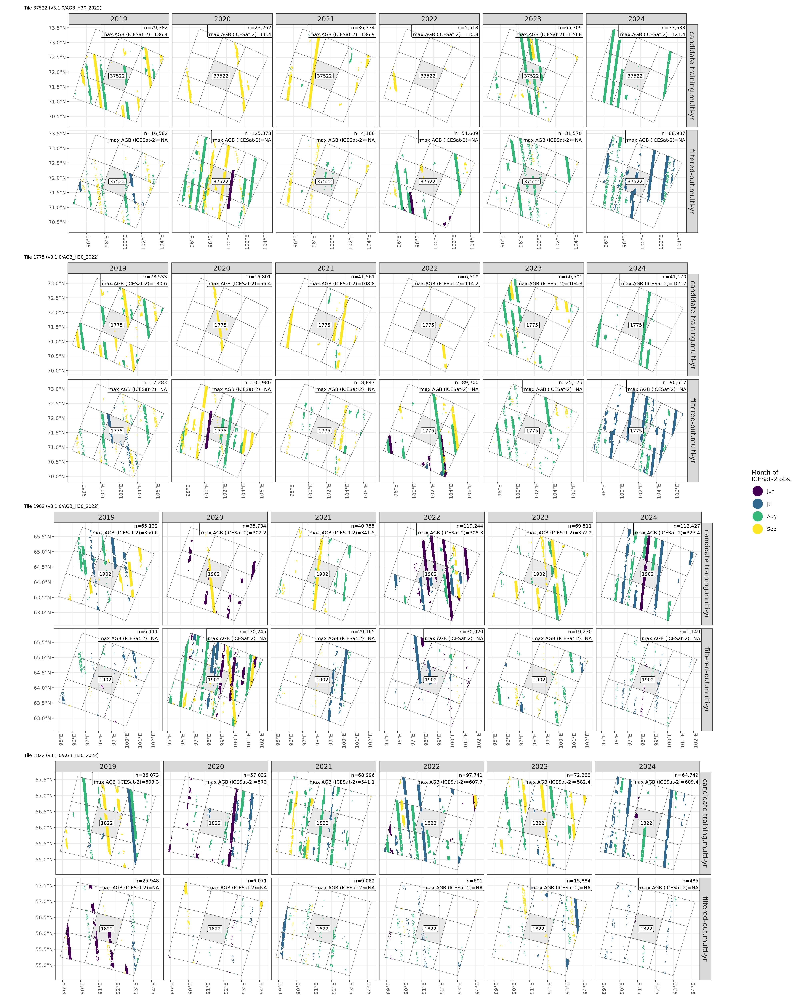

In [66]:
options(repr.plot.width = 20, repr.plot.height = 25, repr.plot.res = 200 , warn = -1 )
AGB_TINDEX_FN = 's3://maap-ops-workspace/shared/montesano/DPS_tile_lists/BOREAL_MAP/v3.1.0/AGB_H30_2022/full_run_niter30_multiyear_atl08v6/AGB_tindex_master.csv'
(
GET_OBS_AND_COMBINE(AGB_TINDEX_FN, 37522, boreal_tiles, MODELLING_STRATEGY='multi-yr') /
GET_OBS_AND_COMBINE(AGB_TINDEX_FN, 1775, boreal_tiles, MODELLING_STRATEGY='multi-yr') /
GET_OBS_AND_COMBINE(AGB_TINDEX_FN, 1902, boreal_tiles, MODELLING_STRATEGY='multi-yr') /
GET_OBS_AND_COMBINE(AGB_TINDEX_FN, 1822, boreal_tiles, MODELLING_STRATEGY='multi-yr') 
    ) + plot_layout(guides = 'collect')

🔍 Searching in bucket: maap-ops-workspace prefix: montesano/dps_output/run_boreal_biomass_map/v3.1.0/AGB_H30_2022/full_run_niter30_multiyear_atl08v6/2025/09/23/15/09/40/576921/ 
✅ Found 2 .parquet file(s):
    s3://maap-ops-workspace/montesano/dps_output/run_boreal_biomass_map/v3.1.0/AGB_H30_2022/full_run_niter30_multiyear_atl08v6/2025/09/23/15/09/40/576921/atl08_006_030m_2019_2024_06_09_filt_covars_merge_neighbors_037522.parquet 
    s3://maap-ops-workspace/montesano/dps_output/run_boreal_biomass_map/v3.1.0/AGB_H30_2022/full_run_niter30_multiyear_atl08v6/2025/09/23/15/09/40/576921/boreal_agb_2022_202509231758664885_0037522_train.parquet 
[1] "modelling_strategy" "obs_class"         


`summarise()` has grouped output by 'modelling_strategy'. You can override
using the `.groups` argument.


🔍 Searching in bucket: maap-ops-workspace prefix: montesano/dps_output/run_boreal_biomass_map/v3.1.0/AGB_H30_2022/full_run_niter30_multiyear_atl08v6/2025/09/11/17/09/53/228975/ 
✅ Found 2 .parquet file(s):
    s3://maap-ops-workspace/montesano/dps_output/run_boreal_biomass_map/v3.1.0/AGB_H30_2022/full_run_niter30_multiyear_atl08v6/2025/09/11/17/09/53/228975/atl08_006_030m_2019_2024_06_09_filt_covars_merge_neighbors_001775.parquet 
    s3://maap-ops-workspace/montesano/dps_output/run_boreal_biomass_map/v3.1.0/AGB_H30_2022/full_run_niter30_multiyear_atl08v6/2025/09/11/17/09/53/228975/boreal_agb_2022_202509111757635428_0001775_train.parquet 
[1] "modelling_strategy" "obs_class"         


`summarise()` has grouped output by 'modelling_strategy'. You can override
using the `.groups` argument.


🔍 Searching in bucket: maap-ops-workspace prefix: montesano/dps_output/run_boreal_biomass_map/v3.1.0/AGB_H30_2022/full_run_niter30_multiyear_atl08v6/2025/09/23/14/48/23/577488/ 
✅ Found 2 .parquet file(s):
    s3://maap-ops-workspace/montesano/dps_output/run_boreal_biomass_map/v3.1.0/AGB_H30_2022/full_run_niter30_multiyear_atl08v6/2025/09/23/14/48/23/577488/atl08_006_030m_2019_2024_06_09_filt_covars_merge_neighbors_001902.parquet 
    s3://maap-ops-workspace/montesano/dps_output/run_boreal_biomass_map/v3.1.0/AGB_H30_2022/full_run_niter30_multiyear_atl08v6/2025/09/23/14/48/23/577488/boreal_agb_2022_202509231758663528_0001902_train.parquet 
[1] "modelling_strategy" "obs_class"         


`summarise()` has grouped output by 'modelling_strategy'. You can override
using the `.groups` argument.


🔍 Searching in bucket: maap-ops-workspace prefix: montesano/dps_output/run_boreal_biomass_map/v3.1.0/AGB_H30_2022/full_run_niter30_multiyear_atl08v6/2025/09/23/14/47/30/675413/ 
✅ Found 2 .parquet file(s):
    s3://maap-ops-workspace/montesano/dps_output/run_boreal_biomass_map/v3.1.0/AGB_H30_2022/full_run_niter30_multiyear_atl08v6/2025/09/23/14/47/30/675413/atl08_006_030m_2019_2024_06_09_filt_covars_merge_neighbors_001822.parquet 
    s3://maap-ops-workspace/montesano/dps_output/run_boreal_biomass_map/v3.1.0/AGB_H30_2022/full_run_niter30_multiyear_atl08v6/2025/09/23/14/47/30/675413/boreal_agb_2022_202509231758663656_0001822_train.parquet 
[1] "modelling_strategy" "obs_class"         


`summarise()` has grouped output by 'modelling_strategy'. You can override
using the `.groups` argument.


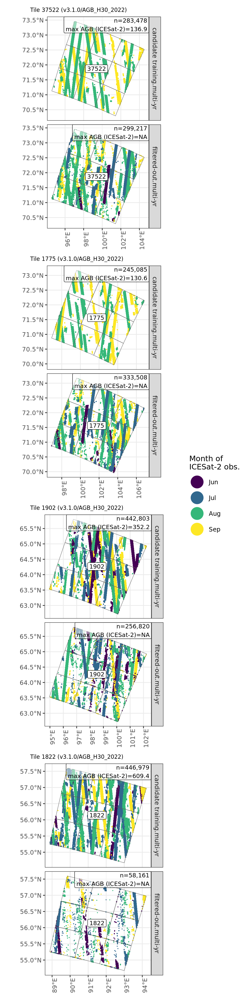

In [183]:
options(repr.plot.width = 5, repr.plot.height = 20, repr.plot.res = 200 , warn = -1 )
AGB_TINDEX_FN = 's3://maap-ops-workspace/shared/montesano/DPS_tile_lists/BOREAL_MAP/v3.1.0/AGB_H30_2022/full_run_niter30_multiyear_atl08v6/AGB_tindex_master.csv'
(
GET_OBS_AND_COMBINE(AGB_TINDEX_FN, 37522, boreal_tiles, MODELLING_STRATEGY='multi-yr', BY_YEAR=FALSE) /
GET_OBS_AND_COMBINE(AGB_TINDEX_FN, 1775, boreal_tiles, MODELLING_STRATEGY='multi-yr', BY_YEAR=FALSE) /
GET_OBS_AND_COMBINE(AGB_TINDEX_FN, 1902, boreal_tiles, MODELLING_STRATEGY='multi-yr', BY_YEAR=FALSE) /
GET_OBS_AND_COMBINE(AGB_TINDEX_FN, 1822, boreal_tiles, MODELLING_STRATEGY='multi-yr', BY_YEAR=FALSE) 
    ) + plot_layout(guides = 'collect')

### Multi-yr obs  

* `TODO` need to look at joins to see if working correctly - seems like training obs are not always a subset of mergeneighbors...
* 

In [109]:
gsub(AGB_multiyr_tindex_master_fn, 'AGB_H30_2020', 'AGB_H30_2016') # This tindex name sub wont matter - b/c the multi-yr model uses data from 2019-2024 regardless of the target AGB year

[1] "AGB_H30_2016"

🔍 Searching in bucket: maap-ops-workspace prefix: montesano/dps_output/run_boreal_biomass_map/v3.1.0/AGB_H30_2020/full_run_niter30_multiyear_atl08v6/2025/09/11/17/23/53/655041/ 
✅ Found 2 .parquet file(s):
    s3://maap-ops-workspace/montesano/dps_output/run_boreal_biomass_map/v3.1.0/AGB_H30_2020/full_run_niter30_multiyear_atl08v6/2025/09/11/17/23/53/655041/atl08_006_030m_2019_2024_06_09_filt_covars_merge_neighbors_001841.parquet 
    s3://maap-ops-workspace/montesano/dps_output/run_boreal_biomass_map/v3.1.0/AGB_H30_2020/full_run_niter30_multiyear_atl08v6/2025/09/11/17/23/53/655041/boreal_agb_2020_202509111757636272_0001841_train.parquet 


`summarise()` has grouped output by 'modelling_strategy', 'obs_class'. You can
override using the `.groups` argument.


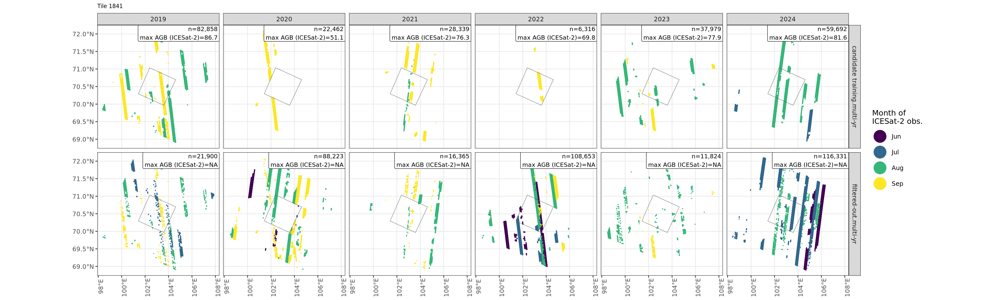

In [36]:
options(repr.plot.width = 20, repr.plot.height = 6, repr.plot.res = 200 , warn = -1 )

multiyr_gdf = GET_OBS_AND_COMBINE(AGB_multiyr_tindex, 3456, boreal_tiles, MODELLING_STRATEGY='multi-yr')

🔍 Searching in bucket: maap-ops-workspace prefix: montesano/dps_output/run_boreal_biomass_map/v3.1.0/AGB_H30_2020/full_run_niter30_multiyear_atl08v6/2025/09/11/16/55/47/967947/ 
✅ Found 2 .parquet file(s):
    s3://maap-ops-workspace/montesano/dps_output/run_boreal_biomass_map/v3.1.0/AGB_H30_2020/full_run_niter30_multiyear_atl08v6/2025/09/11/16/55/47/967947/atl08_006_030m_2019_2024_06_09_filt_covars_merge_neighbors_001209.parquet 
    s3://maap-ops-workspace/montesano/dps_output/run_boreal_biomass_map/v3.1.0/AGB_H30_2020/full_run_niter30_multiyear_atl08v6/2025/09/11/16/55/47/967947/boreal_agb_2020_202509111757634543_0001209_train.parquet 
Using: s3://maap-ops-workspace/montesano/dps_output/run_boreal_biomass_map/v3.1.0/AGB_H30_2020/full_run_niter30_multiyear_atl08v6/2025/09/11/16/55/47/967947/boreal_agb_2020_202509111757634543_0001209_train.parquet 


`summarise()` has grouped output by 'modelling_strategy', 'obs_class'. You can
override using the `.groups` argument.


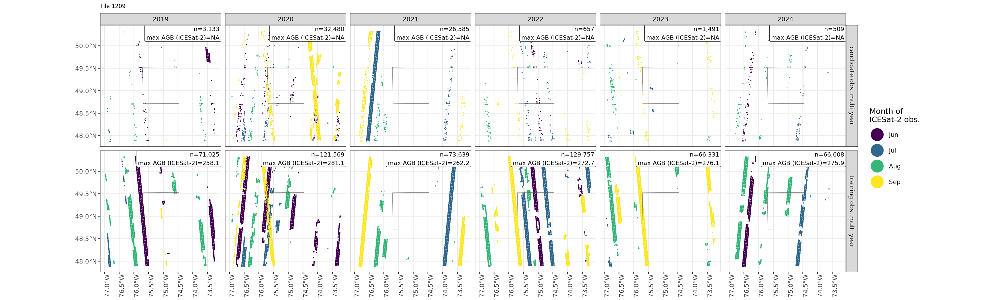

In [29]:
options(repr.plot.width = 20, repr.plot.height = 6, repr.plot.res = 200 , warn = -1 )

multiyr_gdf = GET_OBS_AND_COMBINE(AGB_multiyr_tindex, 1209, boreal_tiles, MODELLING_STRATEGY='multi year')

### Combine dfs and plot

In [445]:
# put single and multi yr gdfs together
all_gdf = rbind(multiyr_gdf, singleyr_gdf) %>%
    mutate(
            y = y.x,
            doy = doy.x,
            modelling_strategy = modelling_strategy.x,
            #file_src = file_src.y, 
            date = as.Date(paste(y.x, doy.x), format = "%Y %j"), # .x b/c they come from mergeneighbors
            month = lubridate::month(date, label = TRUE)
          ) %>%
    dplyr::select(-contains(".x"), -contains(".y"))

In [446]:
smry = all_gdf %>%
    group_by(modelling_strategy, obs_class, y) %>%
    summarise(
        n_obs = n(),
        max_RH_98 = max(RH_98),
        min_RH_98 = min(RH_98),
        mean_RH_98 = mean(RH_98),
        median_RH_98 = median(RH_98),
        max_AGB = max(AGB),
        min_AGB = min(AGB),
        mean_AGB = mean(AGB),
        median_AGB = median(AGB),
        min_doy = min(doy),
        max_doy = max(doy),
        median_doy = median(doy),
        min_year = min(y),
        median_year = median(y),
        max_year = max(y)
    ) %>%
        mutate(
            min_date = as.Date(paste(min_year, min_doy), format = "%Y %j"),
            median_date = as.Date(paste(median_year, median_doy), format = "%Y %j"),
            max_date = as.Date(paste(max_year, max_doy), format = "%Y %j")
        )

`summarise()` has grouped output by 'modelling_strategy', 'obs_class'. You can
override using the `.groups` argument.


In [433]:
head(smry)

modelling_strategy obs_class      y    n_obs  max_RH_98 min_RH_98 mean_RH_98
1 multi year         candidate obs. 2019  21900 NA        NA        NA        
2 multi year         candidate obs. 2020  88223 NA        NA        NA        
3 multi year         candidate obs. 2021  16365 NA        NA        NA        
4 multi year         candidate obs. 2022 108653 NA        NA        NA        
5 multi year         candidate obs. 2023  11824 NA        NA        NA        
6 multi year         candidate obs. 2024 116331 NA        NA        NA        
  median_RH_98 max_AGB min_AGB geometry                       ⋯ min_doy max_doy
1 NA           NA      NA      MULTIPOINT ((102.7954 71.86... ⋯ 194     272    
2 NA           NA      NA      MULTIPOINT ((101.9697 71.96... ⋯ 155     271    
3 NA           NA      NA      MULTIPOINT ((102.9904 71.63... ⋯ 214     268    
4 NA           NA      NA      MULTIPOINT ((102.8071 71.53... ⋯ 163     254    
5 NA           NA      NA      MULTIPOINT ((103.5924 71.58... ⋯ 214     264    
6 NA           NA      NA      MULTIPOINT ((102.4942 71.90... ⋯ 177     239    
  median_doy min_year median_year max_year geometry                      
1 210        2019     2019        2019     MULTIPOINT ((102.7954 71.86...
2 234        2020     2020        2020     MULTIPOINT ((101.9697 71.96...
3 215        2021     2021        2021     MULTIPOINT ((102.9904 71.63...
4 204        2022     2022        2022     MULTIPOINT ((102.8071 71.53...
5 218        2023     2023        2023     MULTIPOINT ((103.5924 71.58...
6 185        2024     2024        2024     MULTIPOINT ((102.4942 71.90...
  min_date   median_date max_date  
1 2019-07-13 2019-07-29  2019-09-29
2 2020-06-03 2020-08-21  2020-09-27
3 2021-08-02 2021-08-03  2021-09-25
4 2022-06-12 2022-07-23  2022-09-11
5 2023-08-02 2023-08-06  2023-09-21
6 2024-06-25 2024-07-03  2024-08-26

In [161]:
library(scales)

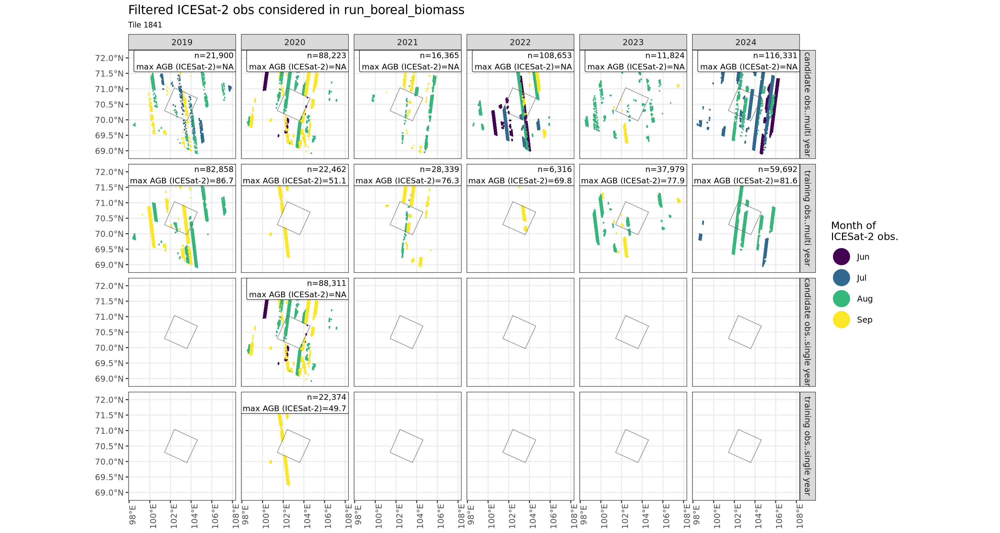

In [447]:
options(repr.plot.width = 15, repr.plot.height = 8, repr.plot.res = 200 , warn = -1 )

map_facets = ggplot(all_gdf #%>% filter(file_src == 'merge neighbors') 
                   )+
    #geom_sf(data=all_gdf %>% filter(file_src == 'both'), color='black', size=2) + 
    geom_sf(aes(color=factor(month)), size=0.01) +
    geom_sf(data=boreal_tiles_focal %>% st_transform(crs=4326), fill=NA) +
    #geom_sf_label(data=boreal_tiles_focal, aes(label=tile_num)) +
    geom_label(data=smry, aes(x=Inf, y=Inf, label=paste0('n=',scales::comma(n_obs),'\nmax AGB (ICESat-2)=',round(max_AGB,1))), hjust=1, vjust=1, size=3) +

    labs(title='Filtered ICESat-2 obs considered in run_boreal_biomass', subtitle=paste0('Tile ',FOCAL_TILE), color='Month of\nICESat-2 obs.') + 
    theme_bw() + 
    #lims(y=c(0, 0.02)) +
    theme(plot.subtitle = element_text(size=8), axis.title = element_blank(), axis.text.x = element_text(angle=90)) + 
    guides(color = guide_legend(override.aes = list(size = 8))) +
    facet_grid(interaction(obs_class,modelling_strategy) ~ y)

map_facets

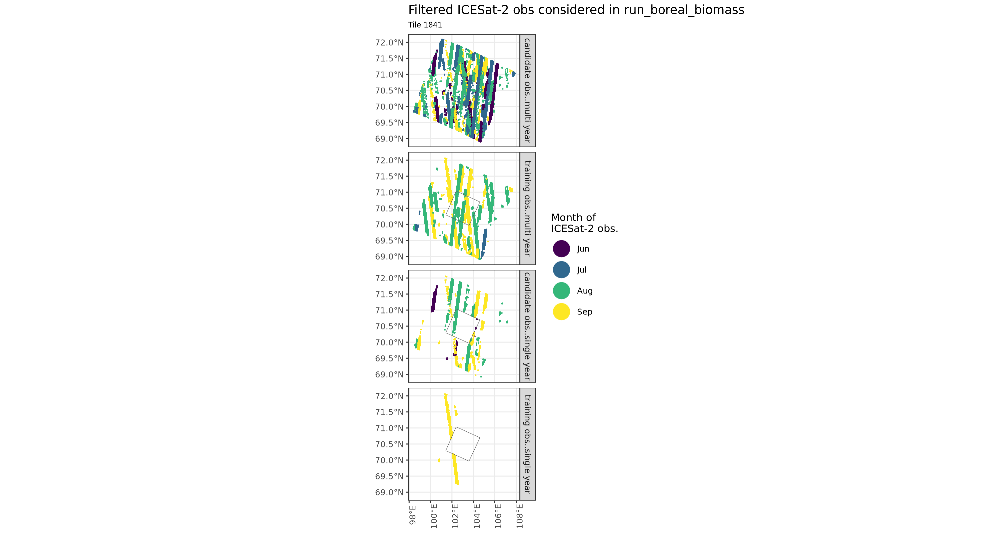

In [448]:
options(repr.plot.width = 15, repr.plot.height = 8, repr.plot.res = 200 , warn = -1 )

map_facets_all_years = ggplot(all_gdf #%>% filter(file_src == 'merge neighbors') 
                   )+
    geom_sf(aes(color=factor(month)), size=0.01) +
    geom_sf(data=boreal_tiles_focal %>% st_transform(crs=4326), fill=NA) +
    #geom_sf_label(data=boreal_tiles_focal, aes(label=tile_num)) +
    #geom_label(data=smry, aes(x=Inf, y=Inf, label=paste0('n=',scales::comma(n_obs),'\nmax AGB (ICESat-2)=',round(max_AGB,1))), hjust=1, vjust=1, size=3) +

    labs(title='Filtered ICESat-2 obs considered in run_boreal_biomass', subtitle=paste0('Tile ',FOCAL_TILE), color='Month of\nICESat-2 obs.') + 
    theme_bw() + 
    #lims(y=c(0, 0.02)) +
    theme(plot.subtitle = element_text(size=8), axis.title = element_blank(), axis.text.x = element_text(angle=90)) + 
    guides(color = guide_legend(override.aes = list(size = 8))) +
    facet_grid(interaction(obs_class,modelling_strategy) ~.)

map_facets_all_years

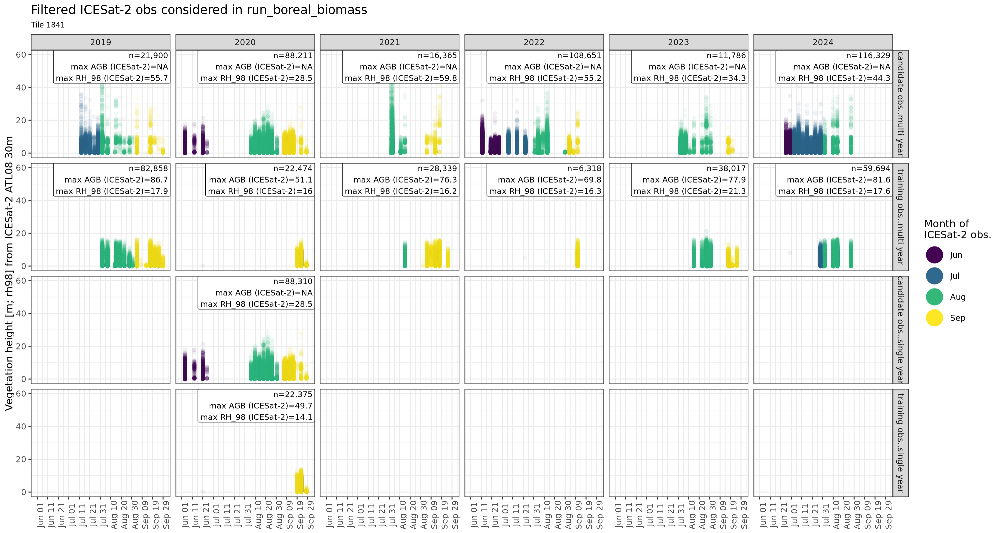

In [183]:
options(repr.plot.width = 15, repr.plot.height = 8, repr.plot.res = 200)

# Create day of year for June 1 and Sept 30 (non-leap year)
june_1_doy <- yday(as.Date("2023-06-01"))  # Day 152
sept_30_doy <- yday(as.Date("2023-09-30")) # Day 273

# Transform your data
all_gdf <- all_gdf %>%
  mutate(day_of_year = yday(date))

ggplot(all_gdf # %>% filter(file_src == 'merge neighbors') 
      )+
    geom_point(aes(x=day_of_year, y=RH_98, color=factor(month))
               #, alpha=0.005
               , alpha = 0.05
              ) +
    geom_label(data=smry, aes(x=Inf, y=Inf, label=paste0('n=',scales::comma(n_obs),'\nmax AGB (ICESat-2)=',round(max_AGB,1), '\nmax RH_98 (ICESat-2)=',round(max_RH_98,1))), hjust=1, vjust=1, size=3) +

  scale_x_continuous(
    limits = c(june_1_doy, sept_30_doy),
    breaks = seq(june_1_doy, sept_30_doy, by = 10), # Every x days
    labels = function(x) {
      dates <- as.Date(x - 1, origin = "2023-01-01")
      format(dates, "%b %d")
    }
  ) +
    labs(title='Filtered ICESat-2 obs considered in run_boreal_biomass', subtitle=paste0('Tile ',FOCAL_TILE), color='Month of\nICESat-2 obs.', y='Vegetation height [m; rh98] from ICESat-2 ATL08 30m', x=NULL) + 
    theme_bw() + 
    #lims(y=c(0, 0.02)) +
    theme(plot.subtitle = element_text(size=8), axis.text.x = element_text(angle=90)) + 
    guides(color = guide_legend(override.aes = list(alpha = 1, size=8))) +
    #facet_grid(modelling_strategy~y, scales='free_x')
    facet_grid(interaction(obs_class,modelling_strategy) ~y, scales='free_x')


### This shows the dates of the ICESat-2 obs for this tile

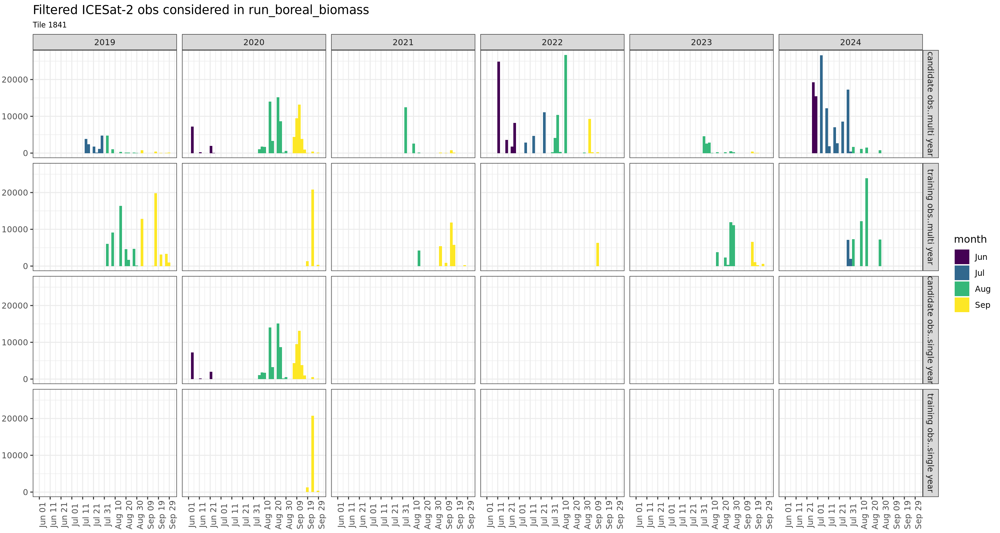

In [184]:
options(repr.plot.width = 15, repr.plot.height = 8, repr.plot.res = 200)

ggplot(all_gdf #%>% filter(file_src == 'merge neighbors') 
      )+
    geom_histogram(aes(x=day_of_year, fill=month), bins=50) +
    #geom_density(aes(x=date, fill=modelling_strategy)) +
    #geom_label(data=smry %>% dplyr::select(!geometry), aes(x=Inf, y=Inf, label=paste0("max AGB =", round(max_AGB,1)) ), hjust=1, vjust=1) +
    # scale_x_date(
    # date_labels = "%b %d %Y",        # Format: Jan 2023
    # date_breaks = "2 weeks",     # Break every 2 months
    # expand = c(0.01, 0)          # Reduce padding
    # ) +
  scale_x_continuous(
    limits = c(june_1_doy, sept_30_doy),
    breaks = seq(june_1_doy, sept_30_doy, by = 10), # Every x days
    labels = function(x) {
      dates <- as.Date(x - 1, origin = "2023-01-01")
      format(dates, "%b %d")
    }
  ) +
    labs(title='Filtered ICESat-2 obs considered in run_boreal_biomass', subtitle=paste0('Tile ',FOCAL_TILE), color='Month of\nICESat-2 obs.', y='Count of ICESat-2 ATL08 30 obs.') + 
    theme_bw() + 
    #lims(y=c(0, 0.02)) +
    theme(plot.subtitle = element_text(size=8), axis.title = element_blank(), axis.text.x = element_text(angle=90)) + 
    #facet_wrap(.~modelling_strategy, ncol=1)
    #facet_grid(modelling_strategy~y, scales='free_x')
    facet_grid(interaction(obs_class,modelling_strategy) ~y, scales='free_x')


In [172]:
(all_gdf %>% mutate(RH_98_rnd8 = round(RH_98, 7)) %>% filter(RH_98_rnd8 == 7.9388123))

,m,y,doy,modelling_strategy,file_src,match_distance,obs_class,RH_98,AGB,date,month,geometry,day_of_year,RH_98_rnd8
,<int>,<int>,<int>,<chr>,<chr>,<dbl>,<chr>,<dbl>,<dbl>,<date>,<ord>,<POINT [°]>,<int>,<dbl>
1,9,2020,266,multi year,merge neighbors,0,training obs.,7.938812,10.69792,2020-09-22,Sep,POINT (102.2816 70.08936),266,7.938812
2,9,2020,266,single year,merge neighbors,0,training obs.,7.938812,10.69792,2020-09-22,Sep,POINT (102.2816 70.08936),266,7.938812


Warning message in st_point_on_surface.sfc(sf::st_zm(x)):
“st_point_on_surface may not give correct results for longitude/latitude data”
Warning message in st_point_on_surface.sfc(sf::st_zm(x)):
“st_point_on_surface may not give correct results for longitude/latitude data”
Warning message in st_point_on_surface.sfc(sf::st_zm(x)):
“st_point_on_surface may not give correct results for longitude/latitude data”
Warning message in st_point_on_surface.sfc(sf::st_zm(x)):
“st_point_on_surface may not give correct results for longitude/latitude data”
Warning message in st_point_on_surface.sfc(sf::st_zm(x)):
“st_point_on_surface may not give correct results for longitude/latitude data”
Warning message in st_point_on_surface.sfc(sf::st_zm(x)):
“st_point_on_surface may not give correct results for longitude/latitude data”
Warning message in st_point_on_surface.sfc(sf::st_zm(x)):
“st_point_on_surface may not give correct results for longitude/latitude data”
Warning message in st_point_on_surface.sf

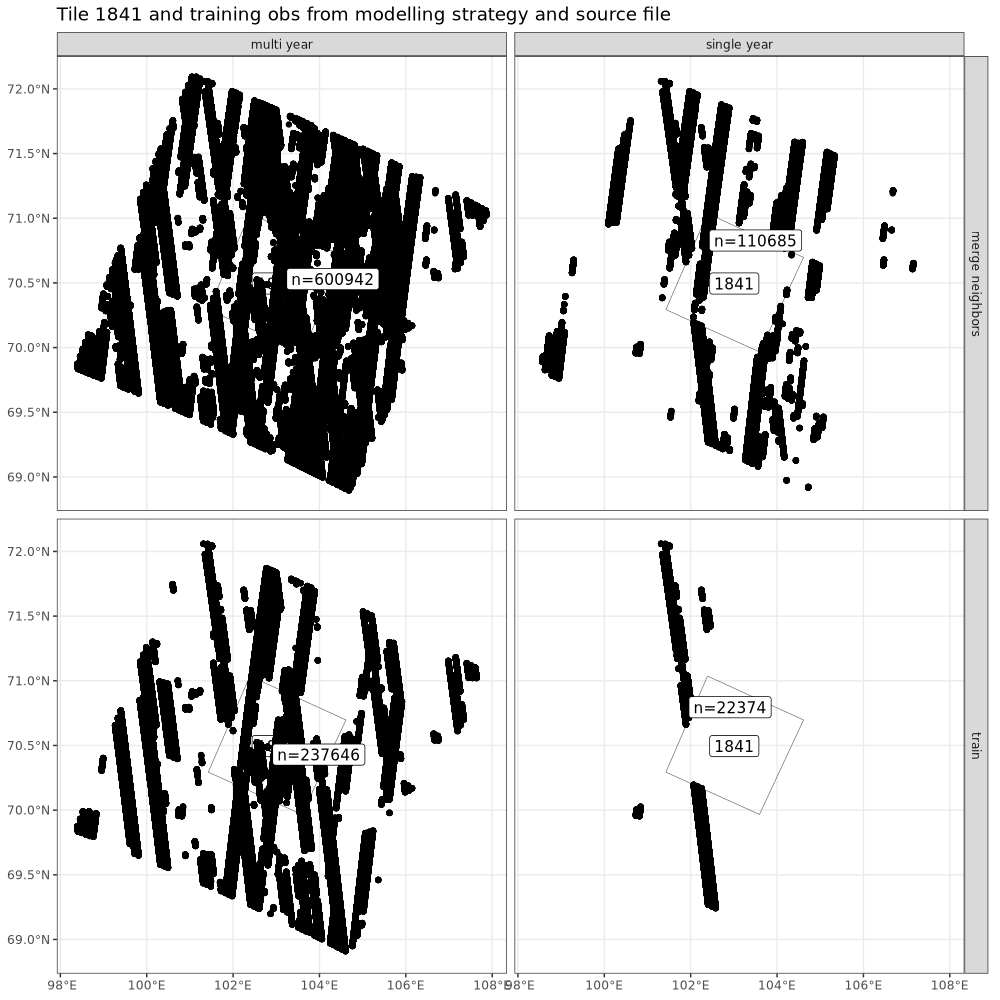

In [30]:
options(repr.plot.width = 10, repr.plot.height = 10, repr.plot.res = 100)

# # The merge_neighbors *.parquet os a geoparquet, but DOES NOT have modeled AGB

map_all = map_focal + 
    geom_sf(data=all_gdf) +
    geom_sf_label(data=smry, aes(x=0, y=0, label=paste0('n=', n_obs)), hjust=0, vjust=0) +
    labs(title=paste0('Tile ',FOCAL_TILE,' and training obs from modelling strategy and source file')) + 
    theme(plot.subtitle = element_text(size=6), axis.title = element_blank()) +
    facet_grid(file_src~modelling_strategy)

map_all

In [31]:

p_hist_all = ggplot(all_gdf) +
    # geom_histogram(aes(x=AGB, fill=modelling_strategy), bins=200) +
    geom_density(aes(x=AGB, fill=modelling_strategy)) +
    geom_label(data=smry %>% dplyr::select(!geometry), aes(x=Inf, y=Inf, label=paste0("max AGB =", round(max_AGB,1)) ), hjust=1, vjust=1) +
    labs(title=paste0('Tile ',FOCAL_TILE)) + 
    theme_bw() + 
    lims(y=c(0, 0.02)) +
    theme(plot.subtitle = element_text(size=8), axis.title = element_blank()) + 
    facet_grid(file_src~modelling_strategy)


Warning message in st_point_on_surface.sfc(sf::st_zm(x)):
“st_point_on_surface may not give correct results for longitude/latitude data”
Warning message in st_point_on_surface.sfc(sf::st_zm(x)):
“st_point_on_surface may not give correct results for longitude/latitude data”
Warning message in st_point_on_surface.sfc(sf::st_zm(x)):
“st_point_on_surface may not give correct results for longitude/latitude data”
Warning message in st_point_on_surface.sfc(sf::st_zm(x)):
“st_point_on_surface may not give correct results for longitude/latitude data”
Warning message in st_point_on_surface.sfc(sf::st_zm(x)):
“st_point_on_surface may not give correct results for longitude/latitude data”
Warning message in st_point_on_surface.sfc(sf::st_zm(x)):
“st_point_on_surface may not give correct results for longitude/latitude data”
Warning message in st_point_on_surface.sfc(sf::st_zm(x)):
“st_point_on_surface may not give correct results for longitude/latitude data”
Warning message in st_point_on_surface.sf

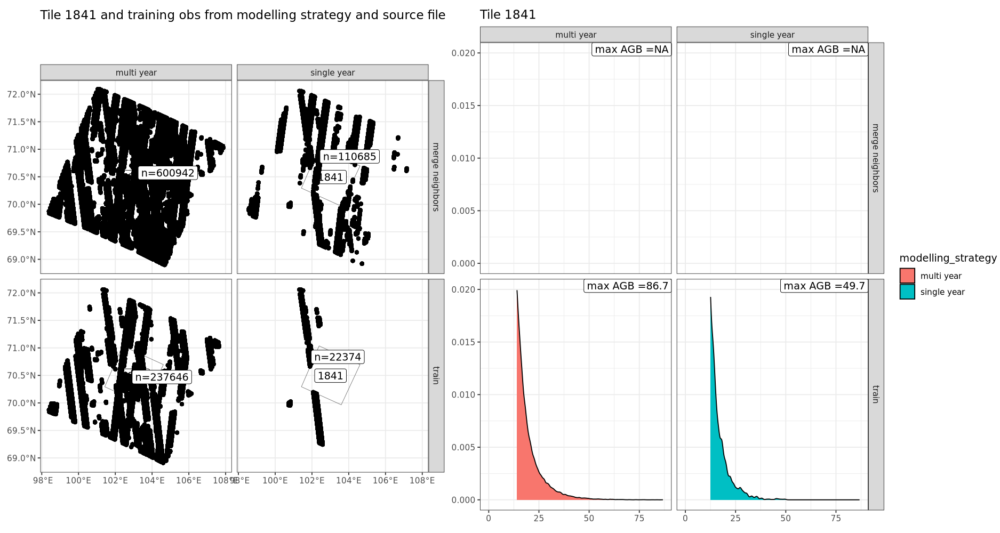

In [32]:
options(repr.plot.width = 15, repr.plot.height = 8, repr.plot.res = 125)

map_all | p_hist_all